# Certificados de residencia: adquisición, ETL y EDA multivariado (ACA 1, v0.1)

**Especialización en Analítica de Datos, CUN.** Integrantes: Mónica Acevedo Sánchez e Ingrid Vanessa López Tautiva.

Este cuaderno desarrolla el objetivo específico 1 con dos fuentes abiertas reales de datos.gov.co: certificados de residencia de la Alcaldía Local 3 de Cartagena y del municipio de Villavicencio.

**Cómo correrlo:** usa *Entorno de ejecución > Ejecutar todo*. Si se abre desde el repositorio, trabaja con las copias fechadas de `data/raw`; si no las encuentra, las descarga de la API.

**Regla de reporte:** ninguna cifra se escribe a mano. Todas salen de este código y quedan en `reports/`.

## 1. Configuración

In [1]:
import hashlib, json, os, re, subprocess, time, unicodedata
from datetime import date, datetime, timezone
from io import StringIO
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats
from sklearn.impute import KNNImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.seasonal import seasonal_decompose

SEMILLA = 42
np.random.seed(SEMILLA)
INICIO_EJECUCION = time.perf_counter()

# Reemplazar por la dirección real del repositorio después de crearlo en GitHub.
REPO_URL = 'https://github.com/monicaacevedos-stack/proyecto_certificados_residencia.git'

if Path('/content').exists() and 'USUARIO' not in REPO_URL and not Path('proyecto_certificados_residencia').exists():
    subprocess.run(['git', 'clone', REPO_URL], check=True)
if Path('proyecto_certificados_residencia').exists():
    os.chdir('proyecto_certificados_residencia')
if Path.cwd().name == 'notebooks':
    os.chdir('..')

BASE = Path.cwd()
RAW, PROC, FIG, TAB = BASE/'data/raw', BASE/'data/processed', BASE/'reports/figures', BASE/'reports/tables'
for carpeta in (RAW, PROC, FIG, TAB):
    carpeta.mkdir(parents=True, exist_ok=True)

FUENTES = {
    'cartagena': {'id': '2muq-8ebv', 'nombre': 'Certificados de Residencia', 'entidad': 'Alcaldía Mayor de Cartagena de Indias (Alcaldía Local 3)', 'enmascarar': ['barrio_corregimiento']},
    'villavicencio': {'id': '38t2-j7vd', 'nombre': 'Certificados de residencia expedidos en el Municipio de Villavicencio', 'entidad': 'Alcaldía de Villavicencio', 'enmascarar': ['barrio', 'comuna_o_corregimiento']},
}

AZUL, NARANJA, AGUA, TINTA, TINTA2, REJILLA = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'savefig.facecolor': 'white',
                     'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': TINTA, 'axes.labelcolor': TINTA2,
                     'axes.edgecolor': REJILLA, 'axes.grid': True, 'axes.axisbelow': True, 'grid.color': REJILLA, 'grid.linewidth': .7,
                     'xtick.color': TINTA2, 'ytick.color': TINTA2, 'xtick.bottom': False, 'ytick.left': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
                     'axes.titlesize': 11.5, 'axes.titleweight': 'bold', 'figure.titlesize': 12, 'legend.frameon': False})

RES = {'interpretaciones': {}, 'titulos_figuras': {}, 'titulos_tablas': {}}

def guardar_tabla(tabla, nombre, titulo, index=False):
    tabla.to_csv(TAB/f'{nombre}.csv', index=index, encoding='utf-8-sig')
    RES['titulos_tablas'][nombre] = titulo
    print(titulo)
    display(tabla)

def guardar_figura(fig, nombre, titulo):
    fig.savefig(FIG/f'{nombre}.png')
    RES['titulos_figuras'][nombre] = titulo
    plt.show()
    plt.close(fig)

def interpretar(clave, texto):
    RES['interpretaciones'][clave] = texto
    print(f'Interpretación ({clave}): {texto}')

def pct(valor, dec=1):
    return f'{valor:.{dec}f}'.replace('.', ',')

def miles(valor):
    return f'{int(round(valor)):,}'.replace(',', '.')

## 2. Adquisición y protección de datos personales

Se descarga por API y **se enmascara antes de guardar**. El texto libre de Villavicencio contiene números de 10 dígitos que parecen identificaciones personales y direcciones. Esos valores nunca se guardan ni se imprimen: solo se conserva el conteo y la huella SHA-256 del archivo original.

In [2]:
RE_ID = re.compile(r'\d{6,}')
RE_DIR = re.compile(r'\b(CRA|CARRERA|KR|CALLE|DIAGONAL|DG|TRANSVERSAL|TV|MZ|MANZANA|CS|CASA|APTO|APARTAMENTO|DTO|LOTE|LT|TORRE)\b.*\d|\d+\s*-\s*\d+', re.I)

def enmascarar(serie):
    texto = serie.astype('object')
    es_id = texto.map(lambda v: isinstance(v, str) and bool(RE_ID.search(v)))
    es_dir = texto.map(lambda v: isinstance(v, str) and bool(RE_DIR.search(v))) & ~es_id
    texto = texto.mask(es_id, '[IDENTIFICADOR_ENMASCARADO]').mask(es_dir, '[DIRECCION_ENMASCARADA]')
    return texto, int(es_id.sum()), int(es_dir.sum())

def adquirir(clave, cfg):
    copias = sorted(RAW.glob(f'{clave}_{cfg["id"]}_*_enmascarado.csv'))
    manifiesto = RAW/f'{clave}_{cfg["id"]}_manifiesto.json'
    if copias and manifiesto.exists():
        return pd.read_csv(copias[-1], dtype=str, encoding='utf-8'), json.loads(manifiesto.read_text(encoding='utf-8')), copias[-1].name
    meta = requests.get(f'https://www.datos.gov.co/api/views/{cfg["id"]}.json', timeout=120).json()
    url = f'https://www.datos.gov.co/resource/{cfg["id"]}.csv'
    r = requests.get(url, params={'$limit': 100000, '$order': ':id'}, timeout=300)
    r.raise_for_status()
    r.encoding = 'utf-8'
    df = pd.read_csv(StringIO(r.text), dtype=str)
    enmasc = {}
    for col in cfg['enmascarar']:
        df[col], n_id, n_dir = enmascarar(df[col])
        enmasc[col] = {'identificadores': n_id, 'direcciones': n_dir}
    hoy = date.today().isoformat()
    nombre = f'{clave}_{cfg["id"]}_{hoy}_enmascarado.csv'
    df.to_csv(RAW/nombre, index=False, encoding='utf-8')
    man = {'dataset_id': cfg['id'], 'nombre': meta.get('name'), 'entidad': cfg['entidad'],
           'enlace': f'https://www.datos.gov.co/d/{cfg["id"]}', 'licencia': (meta.get('license') or {}).get('name') or meta.get('licenseId'),
           'licencia_url': (meta.get('license') or {}).get('termsLink'), 'descripcion': meta.get('description'),
           'fecha_descarga': hoy, 'actualizacion_fuente': datetime.fromtimestamp(meta['rowsUpdatedAt'], timezone.utc).date().isoformat() if meta.get('rowsUpdatedAt') else None,
           'sha256_original_sin_enmascarar': hashlib.sha256(r.content).hexdigest(), 'valores_enmascarados': enmasc,
           'descripciones_columnas': {c['fieldName']: c.get('description', '') for c in meta.get('columns', [])}}
    manifiesto.write_text(json.dumps(man, ensure_ascii=False, indent=2), encoding='utf-8')
    return df, man, nombre

crudos, manifiestos = {}, {}
for clave, cfg in FUENTES.items():
    crudos[clave], manifiestos[clave], archivo = adquirir(clave, cfg)
    print(clave, crudos[clave].shape, '|', archivo, '| licencia:', manifiestos[clave]['licencia'], '|', manifiestos[clave]['valores_enmascarados'])
cart_raw, vill_raw = crudos['cartagena'], crudos['villavicencio']

cartagena (15007, 9) | cartagena_2muq-8ebv_2026-10-31_enmascarado.csv | licencia: Creative Commons Attribution | Share Alike 4.0 International | {'barrio_corregimiento': {'identificadores': 0, 'direcciones': 0}}
villavicencio (11622, 9) | villavicencio_38t2-j7vd_2026-10-31_enmascarado.csv | licencia: Creative Commons Attribution | Share Alike 4.0 International | {'barrio': {'identificadores': 5, 'direcciones': 57}, 'comuna_o_corregimiento': {'identificadores': 0, 'direcciones': 6}}


## 3. ETL/ELT

Se aplican solo reglas deterministas: tipos, duplicados, normalización de texto y variables derivadas. **Aquí no se ajusta ninguna transformación que aprenda de los datos** (imputación, escalado o codificación); esas irán dentro de un Pipeline en el ACA 2.

In [3]:
def sin_acentos(texto):
    return ''.join(c for c in unicodedata.normalize('NFKD', texto) if not unicodedata.combining(c))

def normalizar_texto(serie):
    return serie.map(lambda v: re.sub(r'\s+', ' ', sin_acentos(v).upper()).strip() if isinstance(v, str) else v)

def normalizar_comuna(valor):
    if not isinstance(valor, str):
        return 'Sin clasificar'
    s = re.sub(r'\s+', ' ', sin_acentos(valor).upper()).strip()
    m = re.fullmatch(r'COMUNA ?(\d{1,2})( VILLAVICENCIO)?', s)
    if m and 1 <= int(m.group(1)) <= 10:
        return f'Comuna {int(m.group(1))}'
    m = re.fullmatch(r'CORR?EGIMIENTO ?(?:N ?° ?)?([1-7])(?: - .*)?', s)
    if m:
        return f'Corregimiento {m.group(1)}'
    return 'Sin clasificar'

conteos = []
def registrar(ciudad, paso, df, nota=''):
    faltantes = int(df.isna().sum().sum())
    conteos.append({'Ciudad': ciudad, 'Paso': paso, 'Registros': len(df), 'Variables': df.shape[1], 'Celdas faltantes': faltantes, 'Filas duplicadas': 0 if ciudad == 'Cartagena' and 'codigo_tramite' not in df.columns else int(df.drop(columns='id', errors='ignore').duplicated().sum()), 'Tratamiento': nota})

### 3.1 Cartagena

In [4]:
t0 = time.perf_counter()
c = cart_raw.copy()
c = c.rename(columns={'c_digo_de_tr_mite': 'codigo_tramite', 'calidad_en_la_que_act_a': 'calidad_solicitante', 'barrio_corregimiento': 'barrio',
                      'alcald_a_local': 'alcaldia_local', 'tipo_de_documento_de_identidad': 'tipo_documento',
                      'tiempo_de_residencia_a_o': 'tiempo_residencia_anios', 'juro_que_la_informaci_n': 'juramento'})
registrar('Cartagena', '0. Copia enmascarada', c, 'Sin cambios sobre los registros')
c['fecha_ingreso'] = pd.to_datetime(c['fecha_ingreso'])
c['tiempo_residencia_anios'] = pd.to_numeric(c['tiempo_residencia_anios'])
c['juramento'] = c['juramento'].map({'true': True, 'false': False, 'True': True, 'False': False})
registrar('Cartagena', '1. Tipos de dato', c, 'Fecha, número y booleano')
cod_faltante_c = int(c['codigo_tramite'].eq('No Aplica').sum())
# Los duplicados se buscan con el código presente: sin él, trámites distintos con igual fecha y barrio parecerían la misma fila.
dup_c = int(c.duplicated().sum())
c_con_dup = c.copy()
c = c.drop_duplicates().copy()
registrar('Cartagena', '2. Duplicados exactos', c, 'Se comparan todas las variables, incluido el código; se conserva la primera aparición')
c['codigo_faltante'] = c['codigo_tramite'].eq('No Aplica')
c = c.drop(columns=['alcaldia_local', 'codigo_tramite'])
registrar('Cartagena', '3. Variables sin información analítica', c, 'Se quitan la constante alcaldia_local y codigo_tramite; este último revela el resultado')
barrios_antes = c['barrio'].nunique()
c['barrio'] = normalizar_texto(c['barrio']).str.replace('URBANZACION', 'URBANIZACION', regex=False)
barrios_despues = c['barrio'].nunique()
c['calidad_solicitante'] = normalizar_texto(c['calidad_solicitante'])
registrar('Cartagena', '4. Normalización de texto', c, 'Mayúsculas, acentos, espacios y una errata')
final_c = c['estado'].isin(['Aprobado', 'Aprobado Parcial', 'Rechazado', 'Solicitud Rechazada'])
excluidos_c = c.loc[~final_c, 'estado'].value_counts().to_dict()
c = c[final_c].copy()
c['rechazo'] = c['estado'].isin(['Rechazado', 'Solicitud Rechazada']).astype(int)
registrar('Cartagena', '5. Estados finales y variable objetivo', c, 'Se excluyen Retirado y Presentado, sin decisión final')
q1, q3 = c['tiempo_residencia_anios'].quantile([.25, .75])
lim_inf_c, lim_sup_c = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
c['atipico_tiempo'] = ~c['tiempo_residencia_anios'].between(lim_inf_c, lim_sup_c)
c['anio'] = c['fecha_ingreso'].dt.year
c['mes'] = c['fecha_ingreso'].dt.month
c['dia_semana'] = c['fecha_ingreso'].dt.day_of_week
c['semestre'] = c['anio'].astype(str) + '-S' + ((c['mes'] > 6).astype(int) + 1).astype(str)
c['es_menor'] = c['tipo_documento'].isin(['Tarjeta de identidad', 'Registro civil']).astype(int)
c['es_extranjero'] = c['tipo_documento'].eq('Cédula de extranjería').astype(int)
c['es_representacion'] = c['calidad_solicitante'].str.contains('REPRESENTACION').astype(int)
c = c.sort_values('fecha_ingreso').reset_index(drop=True)
registrar('Cartagena', '6. Atípicos y variables derivadas', c, 'Los atípicos se marcan y se conservan')
seg_etl_c = time.perf_counter() - t0
display(c.head())

,fecha_ingreso,estado,calidad_solicitante,barrio,tipo_documento,tiempo_residencia_anios,juramento,codigo_faltante,rechazo,atipico_tiempo,anio,mes,dia_semana,semestre,es_menor,es_extranjero,es_representacion
0,2024-01-02,Aprobado,A NOMBRE PROPIO,URBANIZACION LA PRINCESA,Cédula de ciudadanía,20.0,True,False,0,False,2024,1,1,2024-S1,0,0,0
1,2024-01-02,Aprobado,A NOMBRE PROPIO,URBANIZACION ALTOS DE SAN PEDRO,Tarjeta de identidad,1.0,True,False,0,False,2024,1,1,2024-S1,1,0,0
2,2024-01-02,Aprobado,A NOMBRE PROPIO,URBANIZACION SIMON BOLIVAR,Cédula de ciudadanía,30.0,True,False,0,False,2024,1,1,2024-S1,0,0,0
3,2024-01-02,Aprobado,A NOMBRE PROPIO,EL SOCORRO,Cédula de ciudadanía,31.0,True,False,0,False,2024,1,1,2024-S1,0,0,0
4,2024-01-03,Aprobado,A NOMBRE PROPIO,SAN PEDRO MARTIR,Cédula de ciudadanía,30.0,True,False,0,False,2024,1,2,2024-S1,0,0,0


### 3.2 Villavicencio

In [5]:
t0 = time.perf_counter()
v = vill_raw.copy()
v = v.rename(columns={'fecha_y_hora_de_la_solicitud': 'fecha_solicitud', 'residente_colombiano': 'tipo_residente', 'comuna_o_corregimiento': 'comuna', 'finalidad_del_certificado': 'finalidad', 'tramite': 'estado'})
registrar('Villavicencio', '0. Copia enmascarada', v, 'Identificadores y direcciones ya enmascarados')
v['fecha_solicitud'] = pd.to_datetime(v['fecha_solicitud'])
registrar('Villavicencio', '1. Tipos de dato', v, 'Fecha y hora')
codigo_1a1 = bool(v.dropna(subset=['estado']).groupby('estado')['estado_del_tramite'].nunique().eq(1).all())
barrios_v_crudos = v['barrio'].nunique()
barrios_v_norm = normalizar_texto(v['barrio']).nunique()
comunas_v_crudas = v['comuna'].nunique()
finalidades_v_crudas = v['finalidad'].nunique()
v = v.drop(columns=['estado_del_tramite'])
registrar('Villavicencio', '2. Variable redundante', v, 'estado_del_tramite es el código de estado')
sin_id = [col for col in v.columns if col != 'id']
dup_v = int(v.duplicated(sin_id).sum())
v = v.drop_duplicates(sin_id).drop(columns=['id']).copy()
registrar('Villavicencio', '3. Duplicados sin contar el id', v, 'Mismo instante y mismos atributos; se quita id, que es un consecutivo')
v['comuna'] = v['comuna'].map(normalizar_comuna)
v['finalidad'] = normalizar_texto(v['finalidad']).replace({'TRAMITE ANTE EMBAJADA': 'ANTE EMBAJADA'})
registrar('Villavicencio', '4. Normalización de categorías', v, 'Comuna y finalidad; lo no interpretable queda como Sin clasificar')
faltante_grupo_v = int(v['grupo_etario'].isna().sum())
faltante_estado_v = int(v['estado'].isna().sum())
v['grupo_etario'] = v['grupo_etario'].fillna('No aplica (PPL)')
v['estado'] = v['estado'].fillna('Sin estado')
faltante_barrio_v = int(v['barrio'].isna().sum())
v = v.drop(columns=['barrio'])
registrar('Villavicencio', '5. Faltantes y texto libre', v, 'Categorías explícitas para faltantes; barrio se retira por riesgo de reidentificación')
v['anio'] = v['fecha_solicitud'].dt.year
v['mes'] = v['fecha_solicitud'].dt.month
v['hora'] = v['fecha_solicitud'].dt.hour
v['dia_semana'] = v['fecha_solicitud'].dt.day_of_week
v['fuera_horario'] = (~v['hora'].between(7, 17) | (v['dia_semana'] >= 5)).astype(int)
v['semestre'] = v['anio'].astype(str) + '-S' + ((v['mes'] > 6).astype(int) + 1).astype(str)
v['es_aprobado'] = v['estado'].eq('Aprobado').astype(int)
v['es_nino'] = v['grupo_etario'].eq('Niños').astype(int)
v['es_ppl'] = v['tipo_residente'].str.contains('privadas').astype(int)
v['es_laboral'] = v['finalidad'].eq('LABORAL').astype(int)
v = v.sort_values('fecha_solicitud').reset_index(drop=True)
registrar('Villavicencio', '6. Variables derivadas', v, 'Calendario, horario e indicadores')
seg_etl_v = time.perf_counter() - t0
display(v.head())

tabla_conteos = pd.DataFrame(conteos)
guardar_tabla(tabla_conteos, 'tabla_etl_conteos', 'Conteos de registros, variables, faltantes y duplicados en cada paso del ETL')
assert (tabla_conteos.groupby('Ciudad')['Registros'].apply(lambda s: s.is_monotonic_decreasing)).all()

,fecha_solicitud,tipo_residente,comuna,grupo_etario,finalidad,estado,anio,mes,hora,dia_semana,fuera_horario,semestre,es_aprobado,es_nino,es_ppl,es_laboral
0,2025-02-26 08:01:00,Residente colombiano,Comuna 4,Adulto,LABORAL,Preaprobado,2025,2,8,2,0,2025-S1,0,0,0,1
1,2025-02-26 08:30:31,Residente colombiano,Comuna 4,Adulto,LABORAL,Preaprobado,2025,2,8,2,0,2025-S1,0,0,0,1
2,2025-02-26 09:05:46,Residente colombiano,Comuna 5,Adulto,LABORAL,Preaprobado,2025,2,9,2,0,2025-S1,0,0,0,1
3,2025-02-26 10:16:36,Residente colombiano,Comuna 9,Adulto,LABORAL,Preaprobado,2025,2,10,2,0,2025-S1,0,0,0,1
4,2025-02-26 10:56:53,Residente colombiano,Comuna 1,Adulto,SEPTIMA BRIGADA(PORTE DE ARMAS),Preaprobado,2025,2,10,2,0,2025-S1,0,0,0,0


Conteos de registros, variables, faltantes y duplicados en cada paso del ETL


,Ciudad,Paso,Registros,Variables,Celdas faltantes,Filas duplicadas,Tratamiento
0,Cartagena,0. Copia enmascarada,15007,9,0,97,Sin cambios sobre los registros
1,Cartagena,1. Tipos de dato,15007,9,0,97,"Fecha, número y booleano"
2,Cartagena,2. Duplicados exactos,14910,9,0,0,"Se comparan todas las variables, incluido el c..."
3,Cartagena,3. Variables sin información analítica,14910,8,0,0,Se quitan la constante alcaldia_local y codigo...
4,Cartagena,4. Normalización de texto,14910,8,0,0,"Mayúsculas, acentos, espacios y una errata"
5,Cartagena,5. Estados finales y variable objetivo,14902,9,0,0,"Se excluyen Retirado y Presentado, sin decisió..."
6,Cartagena,6. Atípicos y variables derivadas,14902,17,0,0,Los atípicos se marcan y se conservan
7,Villavicencio,0. Copia enmascarada,11622,9,100,7,Identificadores y direcciones ya enmascarados
8,Villavicencio,1. Tipos de dato,11622,9,100,7,Fecha y hora
9,Villavicencio,2. Variable redundante,11622,8,87,7,estado_del_tramite es el código de estado


## 4. Ficha del dataset y diccionario de datos

In [6]:
ficha = pd.DataFrame([
    {'Campo': 'Fuente', 'Cartagena': manifiestos['cartagena']['entidad'], 'Villavicencio': manifiestos['villavicencio']['entidad']},
    {'Campo': 'Conjunto de datos', 'Cartagena': manifiestos['cartagena']['nombre'], 'Villavicencio': manifiestos['villavicencio']['nombre']},
    {'Campo': 'Enlace', 'Cartagena': manifiestos['cartagena']['enlace'], 'Villavicencio': manifiestos['villavicencio']['enlace']},
    {'Campo': 'Licencia', 'Cartagena': manifiestos['cartagena']['licencia'], 'Villavicencio': manifiestos['villavicencio']['licencia']},
    {'Campo': 'Fecha de descarga', 'Cartagena': manifiestos['cartagena']['fecha_descarga'], 'Villavicencio': manifiestos['villavicencio']['fecha_descarga']},
    {'Campo': 'Última actualización de la fuente', 'Cartagena': manifiestos['cartagena']['actualizacion_fuente'], 'Villavicencio': manifiestos['villavicencio']['actualizacion_fuente']},
    {'Campo': 'Periodo cubierto', 'Cartagena': f"{c['fecha_ingreso'].min().date()} a {c['fecha_ingreso'].max().date()}", 'Villavicencio': f"{v['fecha_solicitud'].min().date()} a {v['fecha_solicitud'].max().date()}"},
    {'Campo': 'Registros (original / limpio)', 'Cartagena': f'{len(cart_raw)} / {len(c)}', 'Villavicencio': f'{len(vill_raw)} / {len(v)}'},
    {'Campo': 'Variables (original / limpio)', 'Cartagena': f'{cart_raw.shape[1]} / {c.shape[1]}', 'Villavicencio': f'{vill_raw.shape[1]} / {v.shape[1]}'},
    {'Campo': 'Variable objetivo', 'Cartagena': 'rechazo (1 = Rechazado o Solicitud Rechazada; 0 = Aprobado o Aprobado Parcial)', 'Villavicencio': 'No tiene: la fuente no registra rechazos. Se usa para réplica de demanda y calidad.'},
])
guardar_tabla(ficha, 'tabla_ficha_dataset', 'Ficha de los dos conjuntos de datos usados en el proyecto')

DESC = {
 'cartagena': {
  'codigo_tramite': ('Texto', 'Sin unidad', 'Código del trámite; No Aplica cuando no se asignó. Se retira porque revela el resultado.'),
  'fecha_ingreso': ('Fecha', 'Día', 'Fecha en que ingresó la solicitud.'),
  'estado': ('Categórica', 'Sin unidad', 'Estado del trámite en la fuente.'),
  'calidad_solicitante': ('Categórica', 'Sin unidad', 'Si la persona actúa a nombre propio o en representación de otra.'),
  'barrio': ('Categórica', 'Sin unidad', 'Barrio o corregimiento de residencia declarado.'),
  'alcaldia_local': ('Categórica', 'Sin unidad', 'Alcaldía local; es constante y se retira.'),
  'tipo_documento': ('Categórica', 'Sin unidad', 'Tipo de documento; nunca incluye el número.'),
  'tiempo_residencia_anios': ('Numérica', 'Años', 'Tiempo de residencia declarado.'),
  'juramento': ('Booleana', 'Sin unidad', 'Si se marcó el juramento sobre la información.'),
  'codigo_faltante': ('Booleana', 'Sin unidad', 'Derivada: el código original era No Aplica. Excluida de los modelos por fuga.'),
  'rechazo': ('Binaria', 'Sin unidad', 'VARIABLE OBJETIVO: 1 si el trámite fue rechazado.'),
  'atipico_tiempo': ('Booleana', 'Sin unidad', 'Derivada: tiempo de residencia fuera del rango IQR.'),
  'anio': ('Entera', 'Año', 'Derivada de la fecha.'), 'mes': ('Entera', 'Mes', 'Derivada de la fecha.'),
  'dia_semana': ('Entera', 'Día (0 = lunes)', 'Derivada de la fecha.'), 'semestre': ('Categórica', 'Semestre', 'Derivada de la fecha.'),
  'es_menor': ('Binaria', 'Sin unidad', 'Derivada: tarjeta de identidad o registro civil.'),
  'es_extranjero': ('Binaria', 'Sin unidad', 'Derivada: cédula de extranjería.'),
  'es_representacion': ('Binaria', 'Sin unidad', 'Derivada: actúa en representación de otra persona.')},
 'villavicencio': {
  'id': ('Entera', 'Sin unidad', 'Consecutivo de la fuente. Se retira.'),
  'fecha_solicitud': ('Fecha y hora', 'Segundo', 'Momento de la solicitud en línea.'),
  'tipo_residente': ('Categórica', 'Sin unidad', 'Residente colombiano o persona privada de la libertad.'),
  'comuna': ('Categórica', 'Sin unidad', 'Comuna o corregimiento; normalizada a partir de texto libre.'),
  'barrio': ('Texto', 'Sin unidad', 'Texto libre. Se retira por riesgo de reidentificación.'),
  'grupo_etario': ('Categórica', 'Sin unidad', 'Adulto, Niños o No aplica (PPL).'),
  'finalidad': ('Categórica', 'Sin unidad', 'Uso declarado del certificado.'),
  'estado_del_tramite': ('Entera', 'Sin unidad', 'Código numérico del estado; redundante y se retira.'),
  'estado': ('Categórica', 'Sin unidad', 'Estado del trámite en la fuente.'),
  'anio': ('Entera', 'Año', 'Derivada de la fecha.'), 'mes': ('Entera', 'Mes', 'Derivada de la fecha.'),
  'hora': ('Entera', 'Hora', 'Derivada de la fecha.'), 'dia_semana': ('Entera', 'Día (0 = lunes)', 'Derivada de la fecha.'),
  'fuera_horario': ('Binaria', 'Sin unidad', 'Derivada: antes de las 7, desde las 18 o fin de semana.'), 'semestre': ('Categórica', 'Semestre', 'Derivada de la fecha.'),
  'es_aprobado': ('Binaria', 'Sin unidad', 'Derivada: estado Aprobado.'), 'es_nino': ('Binaria', 'Sin unidad', 'Derivada: grupo Niños.'),
  'es_ppl': ('Binaria', 'Sin unidad', 'Derivada: persona privada de la libertad.'), 'es_laboral': ('Binaria', 'Sin unidad', 'Derivada: finalidad laboral.')},
}

def rango(serie):
    if pd.api.types.is_bool_dtype(serie):
        return 'Verdadero / Falso'
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f'{serie.min().date()} a {serie.max().date()}'
    if pd.api.types.is_numeric_dtype(serie):
        return f'{serie.min():g} a {serie.max():g}'
    n = serie.nunique()
    return ' | '.join(map(str, sorted(serie.dropna().unique()))) if n <= 6 else f'{n} categorías'

def diccionario(ciudad, df, crudo, renombres):
    filas = []
    inv = {b: a for a, b in renombres.items()}
    for col, (tipo, unidad, desc) in DESC[ciudad].items():
        en_limpio = col in df.columns
        col_cruda = inv.get(col, col)
        falt = df[col].isna().mean()*100 if en_limpio else (crudo[col_cruda].isna().mean()*100 if col_cruda in crudo.columns else float('nan'))
        faltantes_crudo = crudo[col_cruda].isna().mean()*100 if col_cruda in crudo.columns else float('nan')
        filas.append({'Ciudad': ciudad.capitalize(), 'Variable': col, 'Tipo': tipo, 'Unidad': unidad, 'Descripción': desc,
                      'Valores o rango': rango(df[col]) if en_limpio else 'No se conserva', '% faltantes (original)': round(faltantes_crudo, 2) if pd.notna(faltantes_crudo) else 'Derivada', '% faltantes (limpio)': round(falt, 2) if en_limpio else 'Retirada'})
    return pd.DataFrame(filas)

ren_c = {'c_digo_de_tr_mite': 'codigo_tramite', 'calidad_en_la_que_act_a': 'calidad_solicitante', 'barrio_corregimiento': 'barrio', 'alcald_a_local': 'alcaldia_local', 'tipo_de_documento_de_identidad': 'tipo_documento', 'tiempo_de_residencia_a_o': 'tiempo_residencia_anios', 'juro_que_la_informaci_n': 'juramento'}
ren_v = {'fecha_y_hora_de_la_solicitud': 'fecha_solicitud', 'residente_colombiano': 'tipo_residente', 'comuna_o_corregimiento': 'comuna', 'finalidad_del_certificado': 'finalidad', 'tramite': 'estado'}
dicc = pd.concat([diccionario('cartagena', c, cart_raw, ren_c), diccionario('villavicencio', v, vill_raw, ren_v)], ignore_index=True)
faltan_doc = (set(c.columns) - set(DESC['cartagena'])) | (set(v.columns) - set(DESC['villavicencio']))
assert not faltan_doc, faltan_doc
guardar_tabla(dicc, 'tabla_diccionario', 'Diccionario de datos de las variables originales y derivadas')

Ficha de los dos conjuntos de datos usados en el proyecto


,Campo,Cartagena,Villavicencio
0,Fuente,Alcaldía Mayor de Cartagena de Indias (Alcaldí...,Alcaldía de Villavicencio
1,Conjunto de datos,Certificados de Residencia,Certificados de residencia expedidos en el Mun...
2,Enlace,https://www.datos.gov.co/d/2muq-8ebv,https://www.datos.gov.co/d/38t2-j7vd
3,Licencia,Creative Commons Attribution | Share Alike 4.0...,Creative Commons Attribution | Share Alike 4.0...
4,Fecha de descarga,2026-10-31,2026-10-31
5,Última actualización de la fuente,2026-04-08,2026-04-15
6,Periodo cubierto,2024-01-02 a 2026-03-31,2025-02-26 a 2026-04-14
7,Registros (original / limpio),15007 / 14902,11622 / 11615
8,Variables (original / limpio),9 / 17,9 / 16
9,Variable objetivo,rechazo (1 = Rechazado o Solicitud Rechazada; ...,No tiene: la fuente no registra rechazos. Se u...


Diccionario de datos de las variables originales y derivadas


,Ciudad,Variable,Tipo,Unidad,Descripción,Valores o rango,% faltantes (original),% faltantes (limpio)
0,Cartagena,codigo_tramite,Texto,Sin unidad,Código del trámite; No Aplica cuando no se asi...,No se conserva,0.0,Retirada
1,Cartagena,fecha_ingreso,Fecha,Día,Fecha en que ingresó la solicitud.,2024-01-02 a 2026-03-31,0.0,0.0
2,Cartagena,estado,Categórica,Sin unidad,Estado del trámite en la fuente.,Aprobado | Aprobado Parcial | Rechazado | Soli...,0.0,0.0
3,Cartagena,calidad_solicitante,Categórica,Sin unidad,Si la persona actúa a nombre propio o en repre...,A NOMBRE PROPIO | EN REPRESENTACION DE OTRA PE...,0.0,0.0
4,Cartagena,barrio,Categórica,Sin unidad,Barrio o corregimiento de residencia declarado.,117 categorías,0.0,0.0
5,Cartagena,alcaldia_local,Categórica,Sin unidad,Alcaldía local; es constante y se retira.,No se conserva,0.0,Retirada
6,Cartagena,tipo_documento,Categórica,Sin unidad,Tipo de documento; nunca incluye el número.,Cédula de ciudadanía | Cédula de extranjería |...,0.0,0.0
7,Cartagena,tiempo_residencia_anios,Numérica,Años,Tiempo de residencia declarado.,0 a 64,0.0,0.0
8,Cartagena,juramento,Booleana,Sin unidad,Si se marcó el juramento sobre la información.,Verdadero / Falso,0.0,0.0
9,Cartagena,codigo_faltante,Booleana,Sin unidad,Derivada: el código original era No Aplica. Ex...,Verdadero / Falso,Derivada,0.0


## 5. Diagnóstico de calidad: fallas del dato (objetivo específico 1)

Cada falla se asocia con una característica de ISO/IEC 25012 y se cuenta sobre el dato original. Este catálogo es el insumo para las reglas del script automático del objetivo 2.

In [7]:
n_c, n_v = len(cart_raw), len(vill_raw)
enm_v = manifiestos['villavicencio']['valores_enmascarados']
n_ids = sum(x['identificadores'] for x in enm_v.values())
n_dirs = sum(x['direcciones'] for x in enm_v.values())
comuna_norm_cruda = vill_raw['comuna_o_corregimiento'].map(normalizar_comuna)
sin_clasif = int(comuna_norm_cruda.eq('Sin clasificar').sum())
fuera_patron = int((vill_raw['comuna_o_corregimiento'] != comuna_norm_cruda).sum())
fracc_c = int((pd.to_numeric(cart_raw['tiempo_de_residencia_a_o']) % 1 != 0).sum())
cero_c = int((pd.to_numeric(cart_raw['tiempo_de_residencia_a_o']) == 0).sum())
atip_c = int(c['atipico_tiempo'].sum())
fallas = pd.DataFrame([
 ('Cartagena', 'Código de trámite ausente, escrito como No Aplica', 'Completitud', cod_faltante_c, n_c),
 ('Cartagena', 'Filas idénticas en todas las variables', 'Consistencia', dup_c, n_c),
 ('Cartagena', 'Tiempo de residencia igual a cero', 'Exactitud', cero_c, n_c),
 ('Cartagena', 'Tiempo de residencia con decimales', 'Consistencia', fracc_c, n_c),
 ('Cartagena', 'Tiempo de residencia atípico según IQR', 'Exactitud', atip_c, len(c)),
 ('Villavicencio', 'Identificador personal aparente en texto libre', 'Confidencialidad', n_ids, n_v),
 ('Villavicencio', 'Dirección escrita en campos de barrio o comuna', 'Confidencialidad', n_dirs, n_v),
 ('Villavicencio', 'Comuna escrita fuera del formato estándar', 'Conformidad', fuera_patron, n_v),
 ('Villavicencio', 'Comuna sin clasificar tras normalizar', 'Exactitud', sin_clasif, n_v),
 ('Villavicencio', 'Solicitudes duplicadas al quitar el consecutivo', 'Consistencia', dup_v, n_v),
 ('Villavicencio', 'Estado del trámite vacío', 'Completitud', faltante_estado_v, n_v),
 ('Villavicencio', 'Grupo etario vacío (todas PPL, faltante estructural)', 'Completitud', faltante_grupo_v, n_v),
], columns=['Ciudad', 'Falla', 'Característica ISO/IEC 25012', 'Casos', 'Base'])
fallas['% de la base'] = (fallas['Casos']/fallas['Base']*100).round(2)
guardar_tabla(fallas, 'tabla_fallas_calidad', 'Catálogo de fallas de calidad medidas en los datos originales')

kpi_cal = pd.DataFrame([
 {'Indicador': 'Celdas completas (%)', 'Cartagena antes': round(cart_raw.notna().mean().mean()*100, 2), 'Cartagena después': round(c.notna().mean().mean()*100, 2), 'Villavicencio antes': round(vill_raw.notna().mean().mean()*100, 2), 'Villavicencio después': round(v.notna().mean().mean()*100, 2)},
 {'Indicador': 'Duplicados', 'Cartagena antes': dup_c, 'Cartagena después': 0, 'Villavicencio antes': dup_v, 'Villavicencio después': 0},
 {'Indicador': 'Categorías geográficas', 'Cartagena antes': barrios_antes, 'Cartagena después': barrios_despues, 'Villavicencio antes': comunas_v_crudas, 'Villavicencio después': v['comuna'].nunique()},
 {'Indicador': 'Identificadores y direcciones expuestos', 'Cartagena antes': 0, 'Cartagena después': 0, 'Villavicencio antes': n_ids+n_dirs, 'Villavicencio después': 0},
])
guardar_tabla(kpi_cal, 'tabla_kpi_calidad', 'Indicadores de calidad antes y después del ETL')
seg_etl = seg_etl_c + seg_etl_v
RES.update({'n_cart_raw': n_c, 'n_vill_raw': n_v, 'n_cart': len(c), 'n_vill': len(v), 'dup_c': dup_c, 'dup_v': dup_v, 'n_ids': n_ids, 'n_dirs': n_dirs, 'excluidos_c': excluidos_c,
            'cod_faltante_c': cod_faltante_c, 'barrios_antes': barrios_antes, 'barrios_despues': barrios_despues, 'barrios_v_crudos': barrios_v_crudos, 'barrios_v_norm': barrios_v_norm,
            'comunas_v_crudas': comunas_v_crudas, 'comunas_v_norm': int(v['comuna'].nunique()), 'sin_clasif': sin_clasif, 'fuera_patron': fuera_patron, 'finalidades_v_crudas': finalidades_v_crudas, 'finalidades_v_norm': int(v['finalidad'].nunique()),
            'segundos_etl': round(seg_etl, 3), 'lim_sup_c': lim_sup_c, 'codigo_1a1': codigo_1a1, 'atip_c': atip_c})
print(RES['segundos_etl'], 's de ETL')

Catálogo de fallas de calidad medidas en los datos originales


,Ciudad,Falla,Característica ISO/IEC 25012,Casos,Base,% de la base
0,Cartagena,"Código de trámite ausente, escrito como No Aplica",Completitud,1417,15007,9.44
1,Cartagena,Filas idénticas en todas las variables,Consistencia,97,15007,0.65
2,Cartagena,Tiempo de residencia igual a cero,Exactitud,611,15007,4.07
3,Cartagena,Tiempo de residencia con decimales,Consistencia,802,15007,5.34
4,Cartagena,Tiempo de residencia atípico según IQR,Exactitud,5,14902,0.03
5,Villavicencio,Identificador personal aparente en texto libre,Confidencialidad,5,11622,0.04
6,Villavicencio,Dirección escrita en campos de barrio o comuna,Confidencialidad,63,11622,0.54
7,Villavicencio,Comuna escrita fuera del formato estándar,Conformidad,395,11622,3.40
8,Villavicencio,Comuna sin clasificar tras normalizar,Exactitud,118,11622,1.02
9,Villavicencio,Solicitudes duplicadas al quitar el consecutivo,Consistencia,7,11622,0.06


Indicadores de calidad antes y después del ETL


,Indicador,Cartagena antes,Cartagena después,Villavicencio antes,Villavicencio después
0,Celdas completas (%),100.0,100.0,99.9,100.0
1,Duplicados,97.0,0.0,7.0,0.0
2,Categorías geográficas,117.0,117.0,87.0,18.0
3,Identificadores y direcciones expuestos,0.0,0.0,68.0,0.0


0.61 s de ETL


### Comparación de alternativas: atípicos y duplicados (idea para Excelente)

Son análisis de sensibilidad, no la limpieza final. Muestran cuánto altera cada opción los datos y por qué se elige una.

In [8]:
orig = c['tiempo_residencia_anios']
at = c['atipico_tiempo']
mediana_ctx = pd.Series(orig.where(~at)).groupby([c['barrio'], c['tipo_documento']]).transform('median').fillna(orig[~at].median())
X_knn = pd.DataFrame({'t': orig.where(~at), 'es_menor': c['es_menor'], 'es_ext': c['es_extranjero'], 'rep': c['es_representacion'], 'mes': c['mes']/12, 'freq': c['barrio'].map(c['barrio'].value_counts()/len(c))})
alternativas = {
 'A. Conservar y marcar': orig,
 'B. Recortar al límite IQR': orig.clip(lim_inf_c, lim_sup_c),
 'C. Reemplazar por mediana de registros parecidos': orig.where(~at, mediana_ctx),
 'D. Reemplazar por KNN (k = 5)': pd.Series(KNNImputer(n_neighbors=5).fit_transform(X_knn)[:, 0], index=orig.index),
}
filas = []
for nombre, s in alternativas.items():
    filas.append({'Alternativa': nombre, 'Valores alterados': int((s != orig).sum()), 'Media': round(s.mean(), 3), 'Desv. estándar': round(s.std(), 3), 'P99': round(s.quantile(.99), 2), 'Máximo': round(s.max(), 2),
                  'KS frente al original': round(stats.ks_2samp(orig, s).statistic, 5), 'Spearman con rechazo': round(stats.spearmanr(s, c['rechazo']).statistic, 4)})
tabla_alt = pd.DataFrame(filas)
guardar_tabla(tabla_alt, 'tabla_alternativas_atipicos', 'Efecto de cuatro tratamientos de los atípicos del tiempo de residencia')

base_dup = c_con_dup[c_con_dup['estado'].isin(['Aprobado', 'Aprobado Parcial', 'Rechazado', 'Solicitud Rechazada'])].copy()
base_dup['rechazo'] = base_dup['estado'].isin(['Rechazado', 'Solicitud Rechazada']).astype(int)
base_dup['anio'] = base_dup['fecha_ingreso'].dt.year
sens = pd.DataFrame({'Con duplicados: registros': base_dup.groupby('anio').size(), 'Con duplicados: % rechazo': (base_dup.groupby('anio')['rechazo'].mean()*100).round(2),
                     'Sin duplicados: registros': c.groupby('anio').size(), 'Sin duplicados: % rechazo': (c.groupby('anio')['rechazo'].mean()*100).round(2)}).reset_index().rename(columns={'anio': 'Año'})
guardar_tabla(sens, 'tabla_sensibilidad_duplicados', 'Tasa de rechazo por año con y sin los duplicados exactos de Cartagena')
RES['alt'] = tabla_alt.to_dict('records'); RES['sens'] = sens.to_dict('records')

Efecto de cuatro tratamientos de los atípicos del tiempo de residencia


,Alternativa,Valores alterados,Media,Desv. estándar,P99,Máximo,KS frente al original,Spearman con rechazo
0,A. Conservar y marcar,0,17.131,13.741,53.0,64.0,0.00000,0.0216
1,B. Recortar al límite IQR,5,17.131,13.740,53.0,62.5,0.00034,0.0216
2,C. Reemplazar por mediana de registros parecidos,5,17.117,13.716,52.0,62.0,0.00034,0.0218
3,D. Reemplazar por KNN (k = 5),5,17.117,13.716,52.0,62.0,0.00034,0.0217


Tasa de rechazo por año con y sin los duplicados exactos de Cartagena


,Año,Con duplicados: registros,Con duplicados: % rechazo,Sin duplicados: registros,Sin duplicados: % rechazo
0,2024,6264,10.70,6225,10.14
1,2025,5651,7.18,5628,6.81
2,2026,3084,19.49,3049,18.56


## 6. EDA: variable objetivo y variables principales

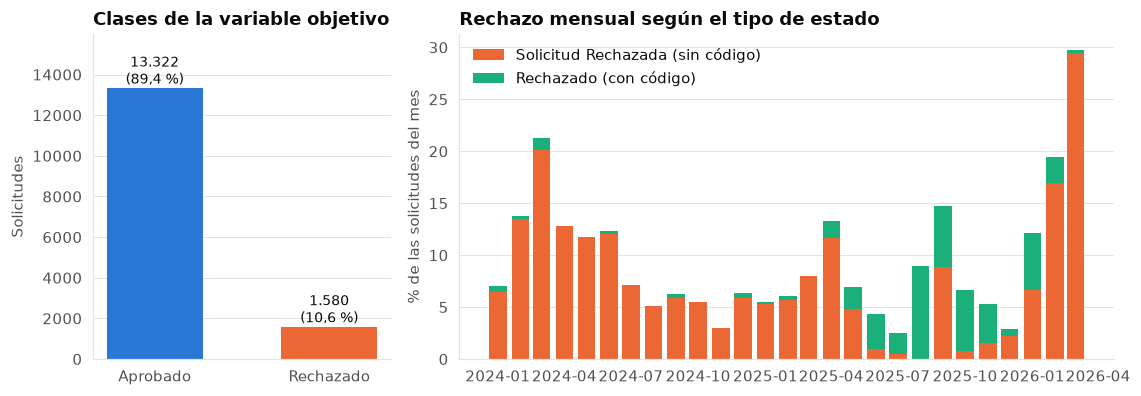

In [9]:
por_anio = c.groupby('anio')['rechazo'].agg(['size', 'mean'])
tasa_global = c['rechazo'].mean()*100
n_rech, n_apr = int(c['rechazo'].sum()), int((1-c['rechazo']).sum())
ratio = n_apr/n_rech
prelim = c['estado'].eq('Solicitud Rechazada')
mens = c.groupby(pd.Grouper(key='fecha_ingreso', freq='MS')).agg(n=('rechazo', 'size'), prelim=('estado', lambda s: (s == 'Solicitud Rechazada').mean()*100), cod=('estado', lambda s: (s == 'Rechazado').mean()*100))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.7), width_ratios=[1, 2.2])
cl = ['Aprobado', 'Rechazado']; vals = [n_apr, n_rech]
b = ax[0].bar(cl, vals, color=[AZUL, NARANJA], width=.55)
for r, val in zip(b, vals):
    ax[0].text(r.get_x()+r.get_width()/2, val, f'{miles(val)}\n({pct(val/len(c)*100)} %)', ha='center', va='bottom', fontsize=9)
ax[0].set_ylim(0, n_apr*1.2); ax[0].set_ylabel('Solicitudes'); ax[0].set_title('Clases de la variable objetivo'); ax[0].grid(axis='x', visible=False)
ax[1].bar(mens.index, mens['prelim'], width=24, color=NARANJA, label='Solicitud Rechazada (sin código)')
ax[1].bar(mens.index, mens['cod'], width=24, bottom=mens['prelim'], color=AGUA, label='Rechazado (con código)')
ax[1].set_ylabel('% de las solicitudes del mes'); ax[1].set_title('Rechazo mensual según el tipo de estado'); ax[1].legend(loc='upper left'); ax[1].grid(axis='x', visible=False)
fig.tight_layout()
guardar_figura(fig, 'fig01_objetivo', 'Distribución de la variable objetivo y tasa mensual de rechazo, Cartagena')
RES.update({'tasa_global': tasa_global, 'n_rech': n_rech, 'n_apr': n_apr, 'ratio': ratio, 'tasa_anio': {int(k): float(v*100) for k, v in por_anio['mean'].items()}, 'prop_prelim': float(prelim.sum()/n_rech*100),
            'mes_max_rech': mens.assign(t=mens.prelim+mens.cod)['t'].idxmax().strftime('%Y-%m'), 'val_max_rech': float((mens.prelim+mens.cod).max())})

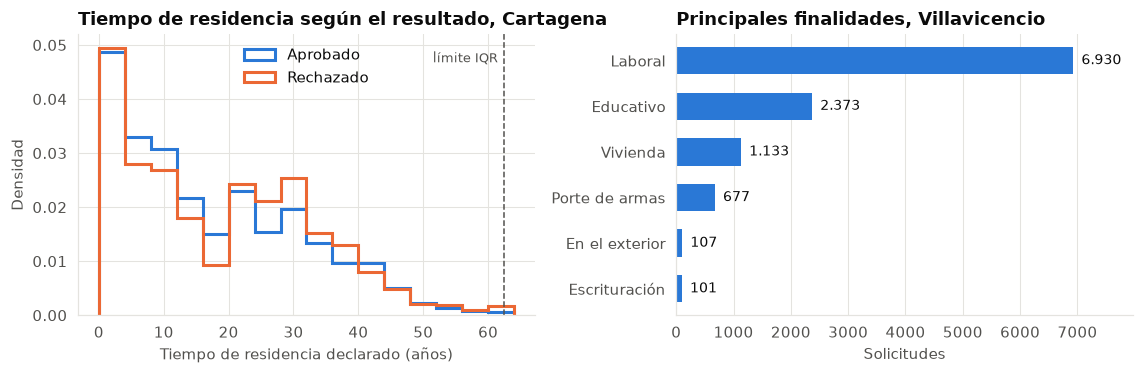

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5))
bins = np.arange(0, 68, 4)
ax[0].hist(c.loc[c.rechazo == 0, 'tiempo_residencia_anios'], bins=bins, density=True, histtype='step', lw=2, color=AZUL, label='Aprobado')
ax[0].hist(c.loc[c.rechazo == 1, 'tiempo_residencia_anios'], bins=bins, density=True, histtype='step', lw=2, color=NARANJA, label='Rechazado')
ax[0].axvline(lim_sup_c, color=TINTA2, ls='--', lw=1); ax[0].text(lim_sup_c-1, ax[0].get_ylim()[1]*.9, 'límite IQR', ha='right', fontsize=8.5, color=TINTA2)
ax[0].set_xlabel('Tiempo de residencia declarado (años)'); ax[0].set_ylabel('Densidad'); ax[0].set_title('Tiempo de residencia según el resultado, Cartagena'); ax[0].legend()
fin = v['finalidad'].value_counts().head(6).sort_values()
etq = {'SEPTIMA BRIGADA(PORTE DE ARMAS)': 'Porte de armas', 'LABORAL': 'Laboral', 'EDUCATIVO': 'Educativo', 'VIVIENDA': 'Vivienda', 'EN EL EXTERIOR': 'En el exterior', 'ESCRITURACION PREDIO': 'Escrituración', 'REDUCCION PEAJE': 'Reducción de peaje'}
ax[1].barh([etq.get(i, i.title()) for i in fin.index], fin.values, color=AZUL, height=.6)
for y, val in enumerate(fin.values):
    ax[1].text(val, y, f'  {miles(val)}', va='center', fontsize=9)
ax[1].set_xlim(0, fin.max()*1.15); ax[1].set_xlabel('Solicitudes'); ax[1].set_title('Principales finalidades, Villavicencio'); ax[1].grid(axis='y', visible=False)
fig.tight_layout()
guardar_figura(fig, 'fig02_variables_principales', 'Distribución del tiempo de residencia en Cartagena y de la finalidad en Villavicencio')
med_apr, med_rec = c.loc[c.rechazo == 0, 'tiempo_residencia_anios'].median(), c.loc[c.rechazo == 1, 'tiempo_residencia_anios'].median()
RES.update({'med_apr': med_apr, 'med_rec': med_rec, 'q_tiempo': c['tiempo_residencia_anios'].describe().to_dict(), 'skew_tiempo': float(c['tiempo_residencia_anios'].skew()),
            'pct_laboral': float(v['es_laboral'].mean()*100), 'top_fin': (v['finalidad'].value_counts(normalize=True).head(3)*100).to_dict(), 'mw_p': float(stats.mannwhitneyu(c.loc[c.rechazo == 0, 'tiempo_residencia_anios'], c.loc[c.rechazo == 1, 'tiempo_residencia_anios']).pvalue)})

## 7. EDA multivariado: correlaciones, multicolinealidad y asociación

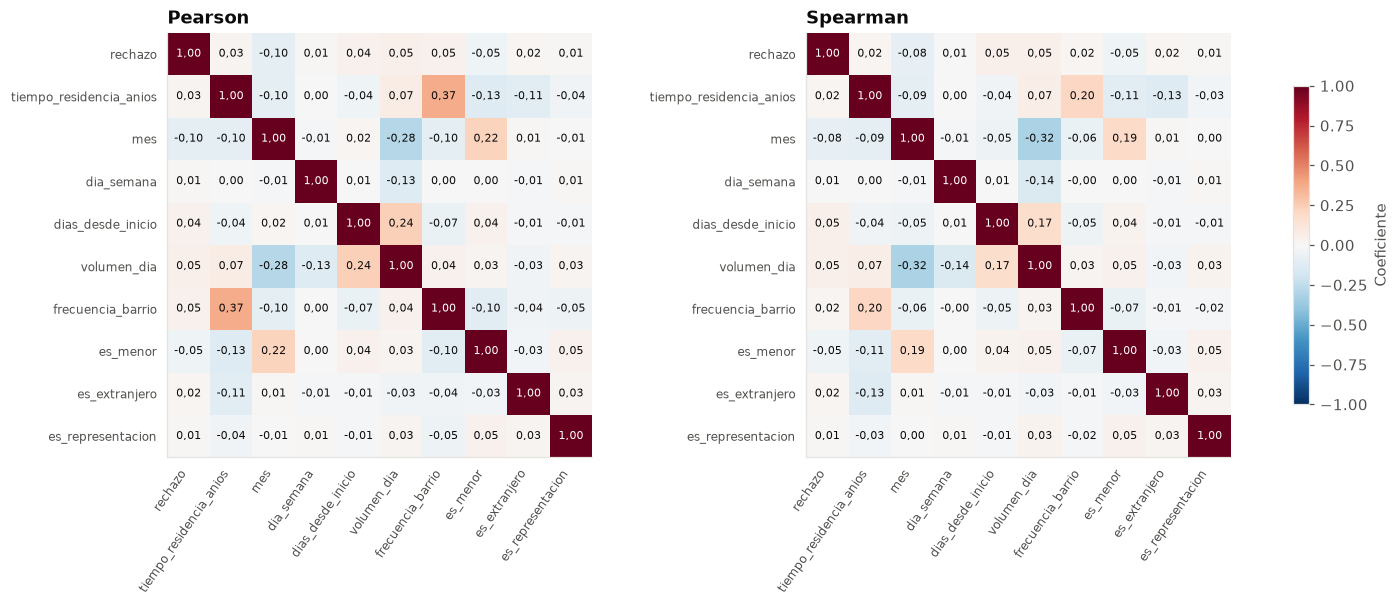

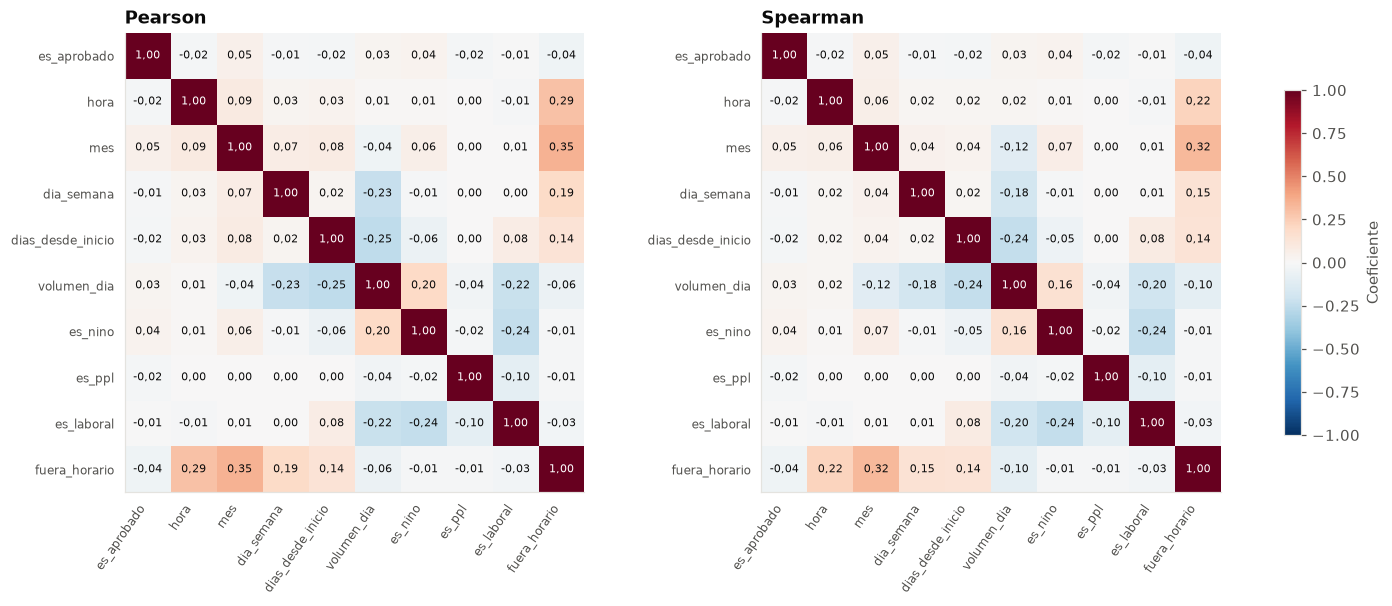

Correlaciones de cada variable con el resultado del trámite


,Ciudad,Variable,Pearson,Spearman,Respecto a
1,Cartagena,tiempo_residencia_anios,0.027,0.022,rechazo
2,Cartagena,mes,-0.097,-0.084,rechazo
3,Cartagena,dia_semana,0.008,0.007,rechazo
4,Cartagena,dias_desde_inicio,0.044,0.053,rechazo
5,Cartagena,volumen_dia,0.051,0.054,rechazo
6,Cartagena,frecuencia_barrio,0.046,0.019,rechazo
7,Cartagena,es_menor,-0.045,-0.045,rechazo
8,Cartagena,es_extranjero,0.017,0.017,rechazo
9,Cartagena,es_representacion,0.012,0.012,rechazo
1,Villavicencio,hora,-0.019,-0.015,es_aprobado


mes                      volumen_dia         -0.319232
tiempo_residencia_anios  frecuencia_barrio    0.204628
mes                      es_menor             0.193409
dias_desde_inicio        volumen_dia          0.174748
dia_semana               volumen_dia         -0.143087
dtype: float64
mes                fuera_horario    0.321166
es_nino            es_laboral      -0.239724
dias_desde_inicio  volumen_dia     -0.238264
hora               fuera_horario    0.219876
volumen_dia        es_laboral      -0.199819
dtype: float64


Factor de inflación de la varianza (VIF) de las variables candidatas


,Ciudad,Variable,VIF
0,Cartagena,tiempo_residencia_anios,1.19
1,Cartagena,mes,1.17
2,Cartagena,dia_semana,1.02
3,Cartagena,dias_desde_inicio,1.08
4,Cartagena,volumen_dia,1.20
5,Cartagena,frecuencia_barrio,1.17
6,Cartagena,es_menor,1.08
7,Cartagena,es_extranjero,1.02
8,Cartagena,es_representacion,1.01
0,Villavicencio,hora,1.10


Asociación de las variables categóricas con el resultado (chi-cuadrado y V de Cramér)


,Ciudad,Variable,Chi-cuadrado,gl,p,V de Cramér
0,Cartagena,anio,290.9,2,6.750000e-64,0.140
4,Cartagena,barrio (20 + otros),231.5,20,6.030000e-38,0.125
1,Cartagena,tipo_documento,43.1,3,2.290000e-09,0.054
3,Cartagena,dia_semana,12.5,6,5.150000e-02,0.029
2,Cartagena,es_representacion,2.1,1,1.460000e-01,0.012
5,Cartagena,atipico_tiempo,0.0,1,9.650000e-01,0.000
6,Villavicencio,mes,117.6,14,1.840000e-18,0.101
8,Villavicencio,comuna,72.5,17,8.050000e-09,0.079
7,Villavicencio,finalidad,52.8,12,4.490000e-07,0.067
9,Villavicencio,grupo_etario,20.8,2,3.040000e-05,0.042


In [11]:
c['dias_desde_inicio'] = (c['fecha_ingreso'] - c['fecha_ingreso'].min()).dt.days
c['volumen_dia'] = c.groupby('fecha_ingreso')['rechazo'].transform('size')
c['frecuencia_barrio'] = c['barrio'].map(c['barrio'].value_counts())
v['fecha_dia'] = v['fecha_solicitud'].dt.normalize()
v['dias_desde_inicio'] = (v['fecha_dia'] - v['fecha_dia'].min()).dt.days
v['volumen_dia'] = v.groupby('fecha_dia')['es_aprobado'].transform('size')
vars_c = ['rechazo', 'tiempo_residencia_anios', 'mes', 'dia_semana', 'dias_desde_inicio', 'volumen_dia', 'frecuencia_barrio', 'es_menor', 'es_extranjero', 'es_representacion']
vars_v = ['es_aprobado', 'hora', 'mes', 'dia_semana', 'dias_desde_inicio', 'volumen_dia', 'es_nino', 'es_ppl', 'es_laboral', 'fuera_horario']

def mapa_corr(df, cols, titulo, nombre):
    pe, sp = df[cols].corr('pearson'), df[cols].corr('spearman')
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
    for a, m, t in zip(ax, (pe, sp), ('Pearson', 'Spearman')):
        im = a.imshow(m.values, cmap='RdBu_r', vmin=-1, vmax=1)
        a.set_xticks(range(len(cols))); a.set_yticks(range(len(cols))); a.set_xticklabels(cols, rotation=55, ha='right', fontsize=8); a.set_yticklabels(cols, fontsize=8); a.grid(False); a.set_title(t)
        for i in range(len(cols)):
            for j in range(len(cols)):
                val = m.values[i, j]
                a.text(j, i, f'{val:.2f}'.replace('.', ','), ha='center', va='center', fontsize=7, color='white' if abs(val) > .6 else TINTA)
    fig.colorbar(im, ax=ax, shrink=.75, label='Coeficiente')
    guardar_figura(fig, nombre, titulo)
    return pe, sp

def pares_fuertes(m, k=5):
    t = m.where(np.triu(np.ones(m.shape, bool), 1)).stack()
    return t.reindex(t.abs().sort_values(ascending=False).index).head(k)

pe_c, sp_c = mapa_corr(c, vars_c, 'Correlaciones de Pearson y Spearman entre variables de Cartagena', 'fig03_correlaciones_cartagena')
pe_v, sp_v = mapa_corr(v, vars_v, 'Correlaciones de Pearson y Spearman entre variables de Villavicencio', 'fig04_correlaciones_villavicencio')
tabla_corr = pd.concat([pd.DataFrame({'Ciudad': ciudad, 'Variable': m.index, 'Pearson': m[obj].round(3).values, 'Spearman': s[obj].round(3).values, 'Respecto a': obj}).query('Variable != @obj') for ciudad, m, s, obj in (('Cartagena', pe_c, sp_c, 'rechazo'), ('Villavicencio', pe_v, sp_v, 'es_aprobado'))])
guardar_tabla(tabla_corr, 'tabla_correlaciones', 'Correlaciones de cada variable con el resultado del trámite')
print(pares_fuertes(sp_c), pares_fuertes(sp_v), sep='\n')

def vif(df, cols):
    X = df[cols].astype(float).assign(constante=1.0)
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(len(cols))], index=cols)

pred_c = [x for x in vars_c if x != 'rechazo']
pred_v = [x for x in vars_v if x != 'es_aprobado']
vif_c, vif_v = vif(c, pred_c), vif(v, pred_v)
tabla_vif = pd.concat([pd.DataFrame({'Ciudad': 'Cartagena', 'Variable': vif_c.index, 'VIF': vif_c.round(2).values}), pd.DataFrame({'Ciudad': 'Villavicencio', 'Variable': vif_v.index, 'VIF': vif_v.round(2).values})])
guardar_tabla(tabla_vif, 'tabla_vif', 'Factor de inflación de la varianza (VIF) de las variables candidatas')

def cramer(x, y):
    tab = pd.crosstab(x, y)
    chi2, p, gl, _ = stats.chi2_contingency(tab)
    return chi2, p, gl, np.sqrt(chi2/(tab.values.sum()*(min(tab.shape)-1)))

top_barrios = c['barrio'].value_counts().head(20).index
cats_c = {'anio': c['anio'], 'tipo_documento': c['tipo_documento'], 'es_representacion': c['es_representacion'], 'dia_semana': c['dia_semana'], 'barrio (20 + otros)': c['barrio'].where(c['barrio'].isin(top_barrios), 'OTROS'), 'atipico_tiempo': c['atipico_tiempo']}
cats_v = {'mes': v['fecha_solicitud'].dt.strftime('%Y-%m'), 'finalidad': v['finalidad'], 'comuna': v['comuna'], 'grupo_etario': v['grupo_etario'], 'fuera_horario': v['fuera_horario']}
filas = []
for ciudad, cats, obj in (('Cartagena', cats_c, c['rechazo']), ('Villavicencio', cats_v, v['es_aprobado'])):
    for nombre, s in cats.items():
        chi2, p, gl, V = cramer(s, obj)
        filas.append({'Ciudad': ciudad, 'Variable': nombre, 'Chi-cuadrado': round(chi2, 1), 'gl': gl, 'p': float(f'{p:.3g}'), 'V de Cramér': round(V, 3)})
tabla_chi = pd.DataFrame(filas).sort_values(['Ciudad', 'V de Cramér'], ascending=[True, False])
guardar_tabla(tabla_chi, 'tabla_asociacion', 'Asociación de las variables categóricas con el resultado (chi-cuadrado y V de Cramér)')
RES.update({'vif_c_max': float(vif_c.max()), 'vif_c_var': vif_c.idxmax(), 'vif_v_max': float(vif_v.max()), 'vif_v_var': vif_v.idxmax(), 'vif_c': vif_c.to_dict(), 'vif_v': vif_v.to_dict(),
            'chi': tabla_chi.to_dict('records'), 'corr': tabla_corr.to_dict('records'),
            'pares_c': {' ~ '.join(k): float(x) for k, x in pares_fuertes(sp_c).items()}, 'pares_v': {' ~ '.join(k): float(x) for k, x in pares_fuertes(sp_v).items()}})

## 8. Tendencia y estacionalidad

Cartagena tiene 27 meses, poco más de dos ciclos anuales, así que la estacionalidad anual es solo indicativa. Villavicencio tiene un año, por lo que allí solo se descompone el ciclo semanal.

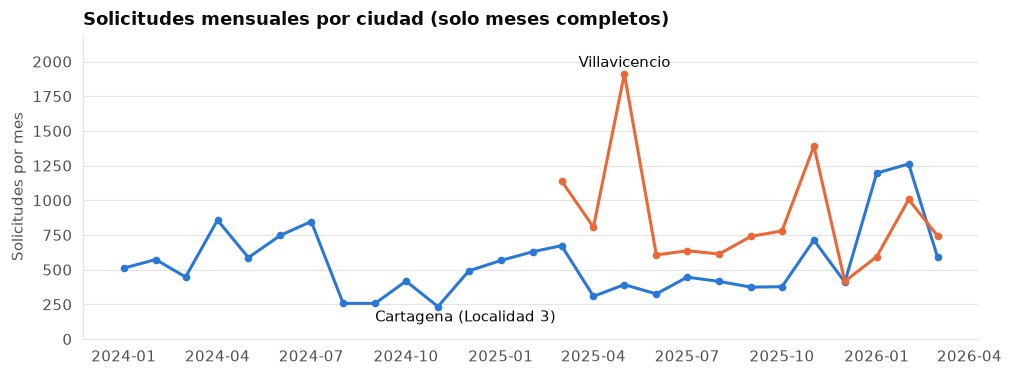

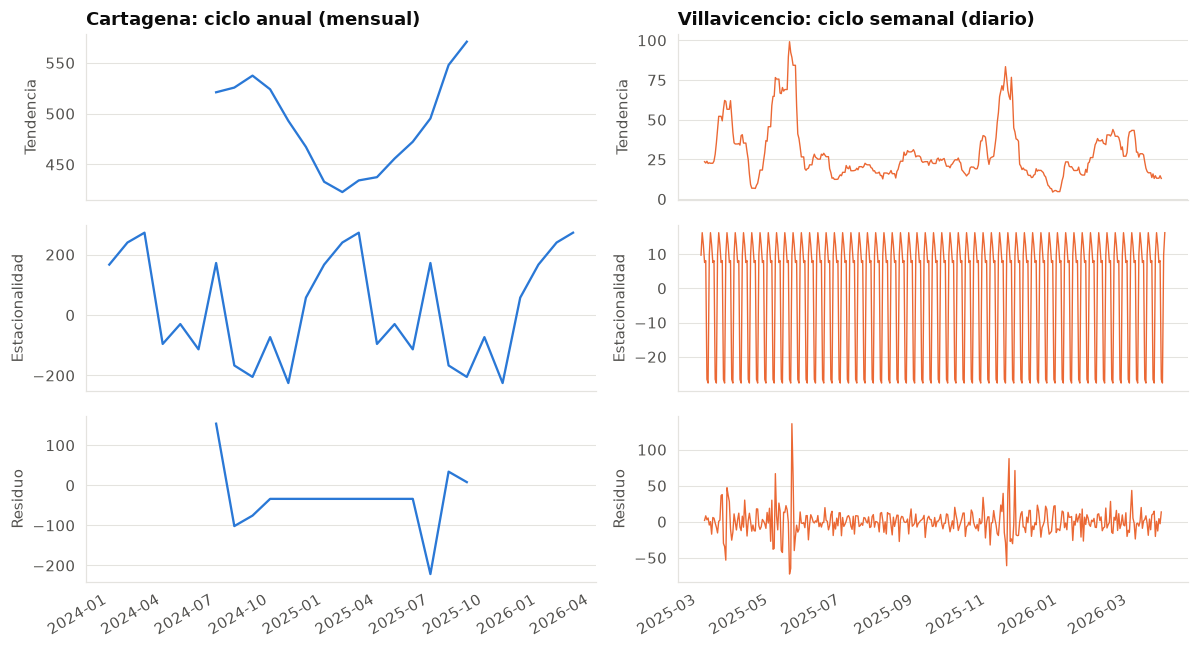

In [12]:
serie_c = c.groupby(pd.Grouper(key='fecha_ingreso', freq='MS')).size()
serie_v = v[(v['fecha_solicitud'] >= '2025-03-01') & (v['fecha_solicitud'] < '2026-04-01')].groupby(pd.Grouper(key='fecha_solicitud', freq='MS')).size()
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.plot(serie_c.index, serie_c.values, color=AZUL, lw=2); ax.plot(serie_v.index, serie_v.values, color=NARANJA, lw=2)
ax.plot(serie_c.index, serie_c.values, 'o', color=AZUL, ms=4); ax.plot(serie_v.index, serie_v.values, 'o', color=NARANJA, ms=4)
ax.text(serie_c.index[8], serie_c.iloc[8]-130, 'Cartagena (Localidad 3)', color=TINTA, fontsize=9.5); ax.text(serie_v.idxmax(), serie_v.max()+50, 'Villavicencio', color=TINTA, fontsize=9.5, ha='center')
ax.set_ylabel('Solicitudes por mes'); ax.set_ylim(0, max(serie_c.max(), serie_v.max())*1.15); ax.grid(axis='x', visible=False)
ax.set_title('Solicitudes mensuales por ciudad (solo meses completos)')
guardar_figura(fig, 'fig05_volumen_mensual', 'Volumen mensual de solicitudes de certificado de residencia en cada ciudad')

dc = seasonal_decompose(serie_c, model='additive', period=12)
diaria_v = v[(v['fecha_solicitud'] >= '2025-03-01') & (v['fecha_solicitud'] < '2026-04-01')].groupby(pd.Grouper(key='fecha_solicitud', freq='D')).size()
dv = seasonal_decompose(diaria_v, model='additive', period=7)
def fuerza(d):
    r = d.resid.dropna(); s = d.seasonal.loc[r.index]
    return max(0, 1 - r.var()/(s+r).var())
def fuerza_t(d):
    r = d.resid.dropna(); t = d.trend.loc[r.index]
    return max(0, 1 - r.var()/(t+r).var())
fig, ax = plt.subplots(3, 2, figsize=(11, 6), sharex='col')
for j, (d, nom) in enumerate(((dc, 'Cartagena: ciclo anual (mensual)'), (dv, 'Villavicencio: ciclo semanal (diario)'))):
    for i, (s, et) in enumerate(((d.trend, 'Tendencia'), (d.seasonal, 'Estacionalidad'), (d.resid, 'Residuo'))):
        ax[i, j].plot(s.index, s.values, color=AZUL if j == 0 else NARANJA, lw=1.5 if j == 0 else .9)
        ax[i, j].set_ylabel(et); ax[i, j].grid(axis='x', visible=False)
    ax[0, j].set_title(nom)
fig.autofmt_xdate(); fig.tight_layout()
guardar_figura(fig, 'fig06_descomposicion', 'Descomposición aditiva de la demanda: tendencia, estacionalidad y residuo')
mes_est_c = dc.seasonal.groupby(dc.seasonal.index.month).first()
RES.update({'fuerza_est_c': fuerza(dc), 'fuerza_tend_c': fuerza_t(dc), 'fuerza_est_v': fuerza(dv), 'fuerza_tend_v': fuerza_t(dv),
            'pico_c': serie_c.idxmax().strftime('%Y-%m'), 'pico_c_n': int(serie_c.max()), 'mediana_c': float(serie_c.median()), 'pico_v': serie_v.idxmax().strftime('%Y-%m'), 'pico_v_n': int(serie_v.max()), 'mediana_v': float(serie_v.median()),
            'meses_top3_c': [d.strftime('%Y-%m') for d in serie_c.sort_values().index[-3:][::-1]], 'meses_top3_v': [d.strftime('%Y-%m') for d in serie_v.sort_values().index[-3:][::-1]], 'corr_meses_comunes': float(serie_c.reindex(serie_v.index).corr(serie_v, method='spearman')),
            'cv_c': float(serie_c.std()/serie_c.mean()), 'cv_v': float(serie_v.std()/serie_v.mean()), 'mes_est_c_max': int(mes_est_c.idxmax()), 'mes_est_c_min': int(mes_est_c.idxmin())})

## 9. ¿Se sostienen los hallazgos? (idea para Excelente)

Se repiten los análisis por año, por semestre y entre ciudades, para ver si un hallazgo depende de un solo corte.

Hallazgos de Cartagena repetidos en cada semestre


,Semestre,Registros,% rechazo,% rechazo sin código,% rechazo con código,Mediana tiempo aprobados,Mediana tiempo rechazados,Spearman tiempo-rechazo,p,% rechazo menores,% rechazo adultos,% fin de semana
0,2024-S1,3722,12.92,12.60,0.32,18.0,20.0,0.019,0.2590,4.76,12.97,7.42
1,2024-S2,2503,5.99,5.87,0.12,12.0,11.0,-0.009,0.6690,5.52,6.06,7.95
2,2025-S1,2893,7.09,6.15,0.93,15.0,20.0,0.045,0.0166,2.27,7.32,8.50
3,2025-S2,2735,6.51,2.12,4.39,12.0,15.0,0.018,0.3390,3.61,6.87,8.78
4,2026-S1,3049,18.56,15.32,3.25,15.1,15.0,-0.012,0.4960,14.29,18.64,8.76


Hallazgos de Villavicencio repetidos en cada semestre


,Semestre,Registros,% Aprobado,% Preaprobado,% laboral,% fuera de horario,% fin de semana
0,2025-S1,4530,37.33,62.60,52.56,0.00,0.00
1,2025-S2,4574,38.43,61.50,63.64,14.12,4.63
2,2026-S1,2511,32.26,67.14,65.23,0.00,0.00


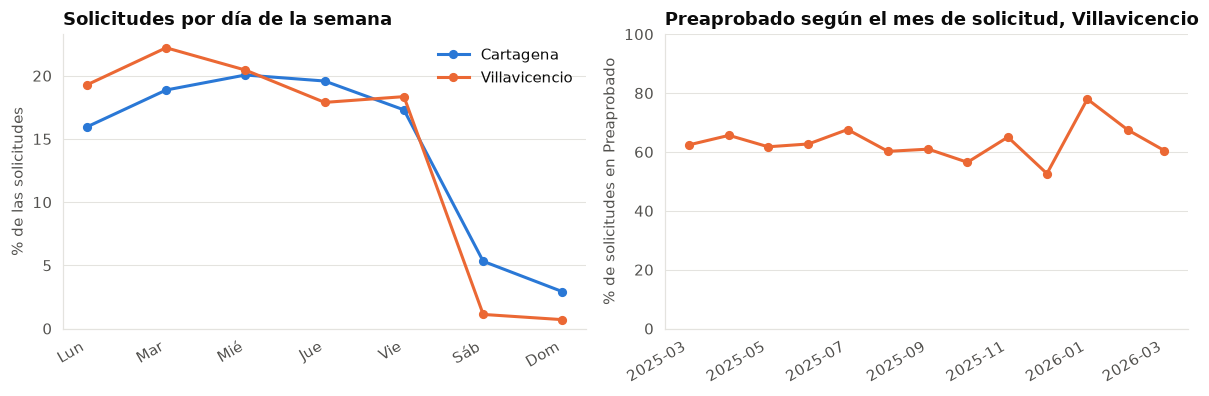

Solicitudes fuera de horario y en fin de semana por mes, Villavicencio


,Mes,Solicitudes,% fuera de horario,% fin de semana
0,2025-02,67,0.00,0.00
1,2025-03,1140,0.00,0.00
2,2025-04,806,0.00,0.00
3,2025-05,1911,0.00,0.00
4,2025-06,606,0.00,0.00
5,2025-07,636,0.00,0.00
6,2025-08,613,0.00,0.00
7,2025-09,740,3.51,1.08
8,2025-10,779,24.90,7.45
9,2025-11,1390,24.89,7.84


Tasa de rechazo (%) por año en los diez barrios con más solicitudes, Cartagena


,Barrio,Registros,2024,2025,2026
0,PASACABALLOS,2741,13.14,11.88,19.58
1,SAN JOSE DE LOS CAMPANOS,967,8.67,2.47,17.14
2,20 DE JULIO,599,16.59,3.39,17.14
3,SAN SEBASTIAN DE TERNERA,552,5.33,4.57,13.89
4,NELSON MANDELA,528,9.90,4.02,15.69
5,URBANIZACION LA CAROLINA,465,2.48,3.41,18.39
6,BLAS DE LEZO ETAPA 1 Y 2,435,3.06,3.36,14.44
7,EL SOCORRO,435,4.31,4.73,12.28
8,SAN FERNANDO,391,8.55,4.76,26.76
9,POLICARPA,379,13.20,14.85,18.52


{'2024-2025': 0.5306703154319574, '2025-2026': 0.47509581106046544, '2024-2026': 0.25354426479171543}


In [13]:
filas = []
for sem, g in c.groupby('semestre'):
    sr = stats.spearmanr(g['tiempo_residencia_anios'], g['rechazo'])
    filas.append({'Semestre': sem, 'Registros': len(g), '% rechazo': round(g['rechazo'].mean()*100, 2), '% rechazo sin código': round(g['estado'].eq('Solicitud Rechazada').mean()*100, 2), '% rechazo con código': round(g['estado'].eq('Rechazado').mean()*100, 2),
                  'Mediana tiempo aprobados': g.loc[g.rechazo == 0, 'tiempo_residencia_anios'].median(), 'Mediana tiempo rechazados': g.loc[g.rechazo == 1, 'tiempo_residencia_anios'].median(), 'Spearman tiempo-rechazo': round(sr.statistic, 3), 'p': float(f'{sr.pvalue:.3g}'),
                  '% rechazo menores': round(g.loc[g.es_menor == 1, 'rechazo'].mean()*100, 2), '% rechazo adultos': round(g.loc[g.es_menor == 0, 'rechazo'].mean()*100, 2), '% fin de semana': round((g['dia_semana'] >= 5).mean()*100, 2)})
rob_c = pd.DataFrame(filas)
guardar_tabla(rob_c, 'tabla_robustez_cartagena', 'Hallazgos de Cartagena repetidos en cada semestre')
filas = []
for sem, g in v.groupby('semestre'):
    filas.append({'Semestre': sem, 'Registros': len(g), '% Aprobado': round(g['es_aprobado'].mean()*100, 2), '% Preaprobado': round(g['estado'].eq('Preaprobado').mean()*100, 2), '% laboral': round(g['es_laboral'].mean()*100, 2), '% fuera de horario': round(g['fuera_horario'].mean()*100, 2), '% fin de semana': round((g['dia_semana'] >= 5).mean()*100, 2)})
rob_v = pd.DataFrame(filas)
guardar_tabla(rob_v, 'tabla_robustez_villavicencio', 'Hallazgos de Villavicencio repetidos en cada semestre')

nombres_dia = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
sem_c = c.groupby('anio')['dia_semana'].value_counts(normalize=True).unstack(0).sort_index()*100
sem_v = v.groupby('anio')['dia_semana'].value_counts(normalize=True).unstack(0).sort_index()*100
est_mes_v = v[(v['fecha_solicitud'] >= '2025-03-01') & (v['fecha_solicitud'] < '2026-04-01')].groupby(pd.Grouper(key='fecha_solicitud', freq='MS'))['estado'].apply(lambda s: s.eq('Preaprobado').mean()*100)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
ax[0].plot(nombres_dia, c['dia_semana'].value_counts(normalize=True).sort_index()*100, color=AZUL, lw=2, marker='o', ms=5, label='Cartagena')
ax[0].plot(nombres_dia, v['dia_semana'].value_counts(normalize=True).sort_index()*100, color=NARANJA, lw=2, marker='o', ms=5, label='Villavicencio')
ax[0].set_ylabel('% de las solicitudes'); ax[0].set_ylim(0); ax[0].set_title('Solicitudes por día de la semana'); ax[0].legend(); ax[0].grid(axis='x', visible=False)
ax[1].plot(est_mes_v.index, est_mes_v.values, color=NARANJA, lw=2, marker='o', ms=5)
ax[1].set_ylim(0, 100); ax[1].set_ylabel('% de solicitudes en Preaprobado'); ax[1].set_title('Preaprobado según el mes de solicitud, Villavicencio'); ax[1].grid(axis='x', visible=False)
fig.autofmt_xdate(); fig.tight_layout()
guardar_figura(fig, 'fig07_patrones_robustez', 'Patrón semanal de demanda en ambas ciudades y estado Preaprobado por mes en Villavicencio')
dias_c, dias_v = c['dia_semana'].value_counts(normalize=True).sort_index(), v['dia_semana'].value_counts(normalize=True).sort_index()
pre = est_mes_v.reset_index(drop=True)
sr_pre = stats.spearmanr(np.arange(len(pre)), pre)
RES.update({'rob_c': rob_c.to_dict('records'), 'rob_v': rob_v.to_dict('records'), 'corr_dias': float(np.corrcoef(dias_c, dias_v)[0, 1]), 'pct_finde_c': float((c.dia_semana >= 5).mean()*100), 'pct_finde_v': float((v.dia_semana >= 5).mean()*100), 'pct_fh_v': float(v.fuera_horario.mean()*100),
            'pre_min': float(est_mes_v.min()), 'pre_max': float(est_mes_v.max()), 'pre_global': float(v.estado.eq('Preaprobado').mean()*100), 'apr_global': float(v.es_aprobado.mean()*100), 'sr_pre': float(sr_pre.statistic), 'sr_pre_p': float(sr_pre.pvalue),
            'rech_menor': float(c.loc[c.es_menor == 1, 'rechazo'].mean()*100), 'rech_adulto': float(c.loc[c.es_menor == 0, 'rechazo'].mean()*100), 'rech_rep': float(c.loc[c.es_representacion == 1, 'rechazo'].mean()*100), 'rech_prop': float(c.loc[c.es_representacion == 0, 'rechazo'].mean()*100),
            'rech_ext': float(c.loc[c.es_extranjero == 1, 'rechazo'].mean()*100)})

# Control de captura: ¿el registro fuera de horario es estable?
horario_v = v.groupby(v['fecha_solicitud'].dt.strftime('%Y-%m')).agg(Solicitudes=('fuera_horario', 'size'), fuera=('fuera_horario', 'mean'), finde=('dia_semana', lambda s: (s >= 5).mean())).reset_index().rename(columns={'fecha_solicitud': 'Mes'})
horario_v['% fuera de horario'] = (horario_v.pop('fuera')*100).round(2)
horario_v['% fin de semana'] = (horario_v.pop('finde')*100).round(2)
guardar_tabla(horario_v, 'tabla_horario_villavicencio', 'Solicitudes fuera de horario y en fin de semana por mes, Villavicencio')

# Persistencia de los barrios con más solicitudes en Cartagena.
tops = c['barrio'].value_counts().head(10).index
bar = c[c['barrio'].isin(tops)].pivot_table(index='barrio', columns='anio', values='rechazo', aggfunc='mean')*100
bar.insert(0, 'Registros', c[c['barrio'].isin(tops)].groupby('barrio').size())
bar = bar.sort_values('Registros', ascending=False).round(2).reset_index().rename(columns={'barrio': 'Barrio'}); bar.columns = [str(x) for x in bar.columns]
guardar_tabla(bar, 'tabla_barrios_rechazo', 'Tasa de rechazo (%) por año en los diez barrios con más solicitudes, Cartagena')
ampl = c[c['barrio'].map(c['barrio'].value_counts()) >= 100].pivot_table(index='barrio', columns='anio', values='rechazo', aggfunc='mean')
corr_barrios = {f'{a}-{b}': float(ampl[a].corr(ampl[b], method='spearman')) for a, b in [(2024, 2025), (2025, 2026), (2024, 2026)]}
RES.update({'n_barrios_100': int(len(ampl)), 'corr_barrios': corr_barrios, 'horario_v': horario_v.to_dict('records'), 'bar': bar.to_dict('records'), 'menor_siempre_menos': bool((rob_c['% rechazo menores'] < rob_c['% rechazo adultos']).all()), 'sem_spearman_signif': int((rob_c['p'] < .05).sum()), 'sem_total': int(len(rob_c)), 'estados_c': cart_raw['estado'].value_counts().to_dict()})
print(corr_barrios)

## 10. Hallazgos e interpretaciones

Los textos toman sus cifras de los resultados, así que se actualizan si los datos cambian.

In [14]:
R = RES
ta = R['tasa_anio']; ta = {int(k): x for k, x in ta.items()}
rc = {x['Semestre']: x for x in R['rob_c']}
chi = {(x['Ciudad'], x['Variable']): x for x in R['chi']}
horario = pd.DataFrame(R['horario_v'])
meses_fh = horario[horario['% fuera de horario'] > 0]['Mes'].tolist()
sem_cod = max(R['rob_c'], key=lambda x: x['% rechazo con código'])
n_doc_fuera = int((v['estado'] == 'Sin estado').sum())
pp = stats.spearmanr(c['tiempo_residencia_anios'], c['rechazo'])
alt_map = {x['Alternativa'][0]: x for x in R['alt']}
filas_v0 = tabla_conteos[tabla_conteos['Ciudad'] == 'Villavicencio']
# Comprobaciones de los enunciados que no llevan cifra: si los datos cambian, hay que revisar el texto.
assert all(x['2026'] > x['2025'] for x in R['bar']) and R['bar'][0]['Barrio'] == 'PASACABALLOS'
assert sum(x['2024'] < R['bar'][0]['2024'] for x in R['bar'][1:]) >= 5 and sum(x['2025'] < R['bar'][0]['2025'] for x in R['bar'][1:]) >= 5
assert all(a['Con duplicados: % rechazo'] > a['Sin duplicados: % rechazo'] for a in R['sens'])
assert c_con_dup[c_con_dup.duplicated()]['estado'].eq('Solicitud Rechazada').all()
assert all(x['% laboral'] > 50 for x in R['rob_v']) and all(x['% Preaprobado'] > 50 for x in R['rob_v'])
assert [x['Semestre'] for x in R['rob_v'] if x['% fuera de horario'] > 0] == ['2025-S2']

interpretar('tabla_ficha_dataset', f"Las dos fuentes son datos reales del mismo trámite, publicados con licencia {manifiestos['cartagena']['licencia']}. Cartagena aporta la variable objetivo porque registra rechazos; Villavicencio no los registra y por eso sirve para replicar el análisis de demanda y de calidad. Ninguna corresponde a Barbosa, así que los resultados se presentan como evidencia de trámites comparables.")
interpretar('tabla_etl_conteos', f"El ETL conserva {miles(R['n_cart'])} de {miles(R['n_cart_raw'])} registros en Cartagena y {miles(R['n_vill'])} de {miles(R['n_vill_raw'])} en Villavicencio, de modo que la limpieza no cambia el tamaño de las bases de manera sensible. Cartagena pierde {R['dup_c']} duplicados exactos y {sum(R['excluidos_c'].values())} trámites sin decisión final. En Villavicencio las celdas faltantes pasan a cero porque se volvieron categorías explícitas y porque se retiró el campo barrio; no hubo imputación.")
interpretar('tabla_fallas_calidad', f"La falla más frecuente en Cartagena es el código ausente ({miles(R['cod_faltante_c'])} casos), que además coincide casi por completo con el estado Solicitud Rechazada. En Villavicencio pesan más la comuna fuera de formato ({R['fuera_patron']} casos) y, por su gravedad, los {R['n_ids']} identificadores aparentes y {R['n_dirs']} direcciones escritas en texto libre. Medir estas fallas responde al objetivo 1 y define las reglas del script del objetivo 2.")
interpretar('tabla_kpi_calidad', f"Las reglas reducen las categorías de comuna en Villavicencio de {R['comunas_v_crudas']} a {R['comunas_v_norm']} y dejan en cero los duplicados y los datos personales detectados. La ausencia de variantes en los {R['barrios_despues']} barrios de Cartagena sugiere que allí el campo se captura con una lista, mientras que en Villavicencio el barrio tiene {miles(R['barrios_v_crudos'])} valores distintos. Estos indicadores miden el estado del dato, no el tiempo ahorrado frente a un proceso manual.")
interpretar('tabla_alternativas_atipicos', f"Solo {R['atip_c']} registros superan el límite IQR de {pct(R['lim_sup_c'])} años, por lo que los cuatro tratamientos casi no cambian la distribución: el estadístico KS máximo es {str(max(x['KS frente al original'] for x in R['alt'])).replace('.', ',')}. Son residencias largas pero posibles, así que se conservan y se marcan. Alterarlas no aporta y quitaría información real.")
s26 = R['sens'][-1]
interpretar('tabla_sensibilidad_duplicados', f"Quitar los {R['dup_c']} duplicados baja la tasa de rechazo en todos los años, porque todos son solicitudes rechazadas sin código: en 2026 pasa de {pct(s26['Con duplicados: % rechazo'], 2)} % a {pct(s26['Sin duplicados: % rechazo'], 2)} %. El patrón entre años no cambia. Como no hay identificador, no se puede distinguir una repetición de un reenvío legítimo, y por eso esta decisión queda registrada como supuesto.")
interpretar('fig01_objetivo', f"La clase rechazo representa {pct(R['tasa_global'])} % de las solicitudes, con {pct(R['ratio'])} aprobadas por cada rechazada; el desbalance justifica no usar exactitud como métrica. La tasa es inestable: {pct(ta[2024])} % en 2024, {pct(ta[2025])} % en 2025 y {pct(ta[2026])} % en 2026, con máximo de {pct(R['val_max_rech'])} % en {R['mes_max_rech']}. También cambia el tipo de rechazo: el estado con código pesa más en {sem_cod['Semestre']}, lo que sugiere un cambio de registro o de criterio que habría que confirmar con la entidad.")
q = R['q_tiempo']
interpretar('fig02_variables_principales', f"El tiempo de residencia tiene asimetría positiva ({pct(R['skew_tiempo'], 2)}) y mediana de {pct(q['50%'])} años. Aprobados y rechazados tienen distribuciones parecidas (medianas de {pct(R['med_apr'])} y {pct(R['med_rec'])} años), de modo que esta variable por sí sola no separa bien el resultado. En Villavicencio, {pct(R['pct_laboral'])} % de las solicitudes tiene finalidad laboral, lo que muestra para qué se usa principalmente el documento.")
pares_c = list(R['pares_c'].items())[0]; pares_v = list(R['pares_v'].items())[0]
corr_c_max = max([x for x in R['corr'] if x['Ciudad'] == 'Cartagena'], key=lambda x: abs(x['Spearman']))
interpretar('fig03_correlaciones_cartagena', f"Ninguna variable numérica tiene una relación monotónica fuerte con el rechazo: la mayor es {corr_c_max['Variable']} con Spearman de {pct(corr_c_max['Spearman'], 3)}. Con el resultado, Pearson y Spearman coinciden en general. Entre predictoras, la asociación más alta según Spearman es {pares_c[0]} ({pct(pares_c[1], 2)}), todavía moderada; tiempo de residencia y frecuencia del barrio difieren más entre coeficientes, lo que sugiere el efecto de los barrios con muchas solicitudes.")
interpretar('fig04_correlaciones_villavicencio', f"El estado Aprobado casi no se relaciona con hora, día o finalidad. La correlación más alta entre variables es {pares_v[0]} ({pct(pares_v[1], 2)}), pero refleja que las solicitudes fuera de horario solo existen entre {meses_fh[0]} y {meses_fh[-1]}. Es un rasgo de la captura de los datos y no del comportamiento de la ciudadanía.")
interpretar('tabla_correlaciones', f"Con ambos coeficientes, las relaciones con el resultado son débiles en las dos ciudades, siempre por debajo de {pct(max(abs(x['Spearman']) for x in R['corr'])+.005, 2)} en valor absoluto. Esto anticipa que un modelo solo con estas variables podría superar por poco a la línea base. Por eso el protocolo fija desde ahora qué mejora se considerará relevante.")
interpretar('tabla_vif', f"El VIF máximo es {pct(R['vif_c_max'], 2)} en Cartagena y {pct(R['vif_v_max'], 2)} en Villavicencio, muy por debajo del umbral habitual de 5. No hay multicolinealidad que obligue a eliminar variables candidatas. volumen_dia y frecuencia_barrio se calculan aquí solo con fines exploratorios y no pasarán así a los modelos, para evitar fuga.")
x1, x2 = chi[('Cartagena', 'anio')], chi[('Cartagena', 'barrio (20 + otros)')]
interpretar('tabla_asociacion', f"En Cartagena, las variables más asociadas con el rechazo son el año (V = {pct(x1['V de Cramér'], 3)}) y el barrio (V = {pct(x2['V de Cramér'], 3)}), ambas con efecto pequeño aunque p sea muy bajo por el tamaño de la muestra. El hecho de que el año encabece la lista refuerza la necesidad de validar en orden temporal. En Villavicencio el resultado se asocia ante todo con el mes (V = {pct(chi[('Villavicencio', 'mes')]['V de Cramér'], 3)}).")
interpretar('fig05_volumen_mensual', f"La demanda se concentra en picos: Cartagena llega a {miles(R['pico_c_n'])} solicitudes en {R['pico_c']} frente a una mediana de {miles(R['mediana_c'])}, y Villavicencio a {miles(R['pico_v_n'])} en {R['pico_v']} frente a {miles(R['mediana_v'])}. En los meses comunes, los picos no coinciden (Spearman de {pct(R['corr_meses_comunes'], 2)}). Por tanto, el calendario de carga debe estimarse para cada municipio.")
interpretar('fig06_descomposicion', f"En Villavicencio el ciclo semanal tiene fuerza moderada ({pct(R['fuerza_est_v'], 2)}), aunque la caída de fin de semana está influida por los meses que no registran esos días. En Cartagena, la fuerza anual calculada ({pct(R['fuerza_est_c'], 2)}) debe leerse con cautela: 27 meses dan poco más de dos ciclos y la descomposición puede atribuir picos aislados a la estacionalidad. Se necesita más historia para afirmar que existe un patrón anual.")
interpretar('fig07_patrones_robustez', f"El patrón semanal se repite en las dos ciudades (correlación de {pct(R['corr_dias'], 2)}), con demanda concentrada de lunes a viernes. En Villavicencio, {pct(R['pre_global'])} % de los registros sigue en Preaprobado y la proporción no baja en los meses más antiguos (Spearman de {pct(R['sr_pre'], 2)} con el orden del mes). Esto sugiere que el estado no es una etapa que se actualice hasta el cierre, o que el cierre no se registra.")
interpretar('tabla_robustez_cartagena', f"Un hallazgo se sostiene: los menores tienen menos rechazo que los adultos en {R['sem_total']} de {R['sem_total']} semestres. En cambio, la relación entre tiempo de residencia y rechazo solo es significativa en {R['sem_spearman_signif']} de {R['sem_total']}, con coeficientes muy bajos, y no debe presentarse como hallazgo general. La tasa global varía de {pct(min(x['% rechazo'] for x in R['rob_c']), 2)} % a {pct(max(x['% rechazo'] for x in R['rob_c']), 2)} %.")
interpretar('tabla_robustez_villavicencio', f"La finalidad laboral predomina en todos los semestres y la proporción de Preaprobado se mantiene alta. El semestre 2025-S2 es el único con solicitudes fuera de horario, de modo que cualquier comparación por hora debe limitarse a periodos con igual forma de registro.")
interpretar('tabla_horario_villavicencio', f"Las solicitudes fuera de horario y en fin de semana solo aparecen de {meses_fh[0]} a {meses_fh[-1]}; todos los demás meses marcan cero. Un corte tan abrupto apunta a un cambio en el sistema o en la forma de registrar la hora, más que a un cambio de conducta. Sin confirmación de la entidad, fuera_horario no debe interpretarse como demanda real.")
cb = R['corr_barrios']
interpretar('tabla_barrios_rechazo', f"Pasacaballos concentra el mayor número de solicitudes y su tasa supera la de la mayoría de los barrios principales en 2024 y 2025. El orden de los barrios es moderadamente estable entre años consecutivos (Spearman de {pct(cb['2024-2025'], 2)} y {pct(cb['2025-2026'], 2)}) y más débil entre 2024 y 2026 ({pct(cb['2024-2026'], 2)}), calculado sobre {R['n_barrios_100']} barrios con al menos 100 registros. El alza de 2026 afecta a todos los barrios de la tabla, por lo que no parece un fenómeno local.")

hallazgos = pd.DataFrame([
 {'Hallazgo': f"El rechazo es inestable: {pct(ta[2025])} % en 2025 y {pct(ta[2026])} % en 2026, en todos los barrios principales y con cambio en el tipo de estado.", 'Decisión que sugiere': 'Confirmar con la entidad si cambiaron los criterios o el registro antes de usar el rechazo como indicador, y validar los modelos en orden temporal.'},
 {'Hallazgo': f"Los picos mensuales llegan a {pct(R['pico_c_n']/R['mediana_c'])} veces la mediana en Cartagena y a {pct(R['pico_v_n']/R['mediana_v'])} en Villavicencio, y no coinciden entre ciudades.", 'Decisión que sugiere': 'Estimar el calendario de carga de cada municipio y programar personal y procesos automáticos en sus periodos pico.'},
 {'Hallazgo': f"El texto libre concentra las peores fallas: {miles(R['barrios_v_crudos'])} escrituras de barrio, {R['comunas_v_crudas']} de comuna y {R['n_ids']+R['n_dirs']} valores con identificador o dirección en Villavicencio.", 'Decisión que sugiere': 'En Barbosa, capturar barrio y comuna con listas cerradas y revisar datos personales con un script antes de publicar cualquier archivo.'},
])
guardar_tabla(hallazgos, 'tabla_hallazgos_decisiones', 'Tres hallazgos del EDA y la decisión que sugiere cada uno')

Interpretación (tabla_ficha_dataset): Las dos fuentes son datos reales del mismo trámite, publicados con licencia Creative Commons Attribution | Share Alike 4.0 International. Cartagena aporta la variable objetivo porque registra rechazos; Villavicencio no los registra y por eso sirve para replicar el análisis de demanda y de calidad. Ninguna corresponde a Barbosa, así que los resultados se presentan como evidencia de trámites comparables.
Interpretación (tabla_etl_conteos): El ETL conserva 14.902 de 15.007 registros en Cartagena y 11.615 de 11.622 en Villavicencio, de modo que la limpieza no cambia el tamaño de las bases de manera sensible. Cartagena pierde 97 duplicados exactos y 8 trámites sin decisión final. En Villavicencio las celdas faltantes pasan a cero porque se volvieron categorías explícitas y porque se retiró el campo barrio; no hubo imputación.
Interpretación (tabla_fallas_calidad): La falla más frecuente en Cartagena es el código ausente (1.417 casos), que además coincid

,Hallazgo,Decisión que sugiere
0,"El rechazo es inestable: 6,8 % en 2025 y 18,6 ...",Confirmar con la entidad si cambiaron los crit...
1,"Los picos mensuales llegan a 2,6 veces la medi...",Estimar el calendario de carga de cada municip...
2,El texto libre concentra las peores fallas: 2....,"En Barbosa, capturar barrio y comuna con lista..."


## 11. Protocolo de evaluación

Se fija antes de entrenar cualquier modelo. Cualquier cambio posterior debe justificarse en la bitácora de decisiones.

In [15]:
protocolo = pd.DataFrame([
 {'Elemento': 'Enfoque y variable objetivo', 'Definición': 'Predictivo, clasificación binaria de rechazo en Cartagena. Villavicencio no entra al modelo porque no registra rechazos.'},
 {'Elemento': 'Métrica principal', 'Definición': 'F1-macro: da igual peso a aprobados y rechazados, necesario por el desbalance de clases.'},
 {'Elemento': 'Métricas secundarias', 'Definición': 'AUC-PR, MCC y sensibilidad de la clase rechazo.'},
 {'Elemento': 'Partición y validación', 'Definición': 'Último 20 % de los registros por fecha como prueba final; TimeSeriesSplit con 10 cortes sobre el 80 % anterior. No se mezcla el orden porque la tasa cambia en el tiempo.'},
 {'Elemento': 'Línea base', 'Definición': 'Predecir siempre la clase más frecuente (aprobado), evaluada en los mismos cortes. Referencia adicional: predecir según la tasa de rechazo del periodo anterior.'},
 {'Elemento': 'Criterio de éxito', 'Definición': 'Superar la línea base en F1-macro por al menos 0,05, con intervalos de confianza del 95 % que no se crucen en los cortes temporales, y confirmarlo en la prueba final.'},
 {'Elemento': 'Prueba estadística', 'Definición': 'Friedman con Nemenyi para tres o más modelos; Wilcoxon con corrección de Holm para comparaciones por pares, sobre los 10 cortes (con 5 cortes Wilcoxon no puede llegar a p < 0,05).'},
 {'Elemento': 'Control de fuga de información', 'Definición': 'Se excluyen codigo_tramite, codigo_faltante, estado, volumen_dia y frecuencia_barrio calculada sobre toda la base. Imputación, escalado y codificación se ajustan dentro de un Pipeline, solo con los datos de entrenamiento de cada corte.'},
])
guardar_tabla(protocolo, 'tabla_protocolo', 'Protocolo de evaluación fijado antes de entrenar modelos')
kpis = pd.DataFrame([
 {'Indicador': 'Completitud', 'Fórmula': 'Celdas no vacías / celdas totales × 100', 'Referencia': 'Valor en la copia original'},
 {'Indicador': 'Unicidad', 'Fórmula': 'Registros sin duplicado / registros × 100', 'Referencia': 'Valor en la copia original'},
 {'Indicador': 'Conformidad de comuna', 'Fórmula': 'Valores con formato estándar / registros × 100', 'Referencia': 'Valor en la copia original'},
 {'Indicador': 'Datos personales expuestos', 'Fórmula': 'Valores detectados con identificador o dirección', 'Referencia': 'Meta: cero'},
 {'Indicador': 'Tiempo de ejecución', 'Fórmula': 'Segundos del ETL por lote', 'Referencia': 'Medición manual cronometrada; aún no existe y debe obtenerse para comparar'},
])
guardar_tabla(kpis, 'tabla_kpi_complementarios', 'Indicadores complementarios de calidad para evaluar la automatización')

Protocolo de evaluación fijado antes de entrenar modelos


,Elemento,Definición
0,Enfoque y variable objetivo,"Predictivo, clasificación binaria de rechazo e..."
1,Métrica principal,F1-macro: da igual peso a aprobados y rechazad...
2,Métricas secundarias,"AUC-PR, MCC y sensibilidad de la clase rechazo."
3,Partición y validación,Último 20 % de los registros por fecha como pr...
4,Línea base,Predecir siempre la clase más frecuente (aprob...
5,Criterio de éxito,Superar la línea base en F1-macro por al menos...
6,Prueba estadística,Friedman con Nemenyi para tres o más modelos; ...
7,Control de fuga de información,"Se excluyen codigo_tramite, codigo_faltante, e..."


Indicadores complementarios de calidad para evaluar la automatización


,Indicador,Fórmula,Referencia
0,Completitud,Celdas no vacías / celdas totales × 100,Valor en la copia original
1,Unicidad,Registros sin duplicado / registros × 100,Valor en la copia original
2,Conformidad de comuna,Valores con formato estándar / registros × 100,Valor en la copia original
3,Datos personales expuestos,Valores detectados con identificador o dirección,Meta: cero
4,Tiempo de ejecución,Segundos del ETL por lote,Medición manual cronometrada; aún no existe y ...


## 12. Bitácora de decisiones (anexo)

In [16]:
fd = manifiestos['cartagena']['fecha_descarga']
bitacora = pd.DataFrame([
 (fd, 'Usar datos abiertos de Cartagena y Villavicencio', 'Pedir el Excel de Barbosa; usar datos sintéticos', 'La página de datos abiertos de Barbosa no publica este trámite y la guía exige datos reales', 'Sección 2; tabla_ficha_dataset'),
 (fd, 'Enmascarar antes de guardar cualquier copia', 'Publicar la copia cruda; borrar los registros afectados', f"Se detectaron {R['n_ids']} identificadores aparentes y {R['n_dirs']} direcciones; el repositorio será público", 'Manifiesto; tabla_fallas_calidad'),
 (fd, 'Definir rechazo como variable objetivo en Cartagena', 'Pronosticar volumen; enfoque solo descriptivo', 'Es la única salida del trámite con clases definidas', 'fig01_objetivo'),
 (fd, 'Excluir codigo_tramite de los modelos', 'Usarlo como variable', f"El valor No Aplica coincide casi siempre con Solicitud Rechazada ({miles(R['cod_faltante_c'])} casos): sería fuga", 'tabla_fallas_calidad'),
 (fd, 'Buscar duplicados antes de quitar el código', 'Buscarlos después de quitarlo', f"Después de quitarlo, trámites distintos parecían iguales y se inflaba el conteo; con el código son {R['dup_c']}", 'tabla_etl_conteos'),
 (fd, 'Conservar y marcar los atípicos', 'Recortar, mediana de parecidos, KNN', f"Solo son {R['atip_c']} casos, plausibles, y las alternativas casi no cambian la distribución", 'tabla_alternativas_atipicos'),
 (fd, 'Dejar comunas no interpretables como Sin clasificar', 'Asumir que un número suelto es una comuna', 'Un número suelto podría ser otra cosa; no se inventa información', 'tabla_kpi_calidad'),
 (fd, 'Retirar barrio de Villavicencio de la base limpia', 'Normalizarlo con coincidencia aproximada', 'Texto libre con riesgo de reidentificación y poco valor para el objetivo', 'tabla_kpi_calidad'),
 (fd, 'Usar TimeSeriesSplit con 10 cortes', 'Validación cruzada aleatoria 5×2; 5 cortes temporales', 'La tasa cambia en el tiempo y Wilcoxon con 5 cortes no alcanza significancia', 'tabla_robustez_cartagena; tabla_protocolo'),
 (fd, 'No interpretar fuera_horario como demanda real', 'Analizarlo como conducta ciudadana', f"Solo existe de {meses_fh[0]} a {meses_fh[-1]}, lo que apunta a un cambio de registro", 'tabla_horario_villavicencio'),
], columns=['Fecha', 'Decisión', 'Alternativas consideradas', 'Por qué se eligió', 'Evidencia'])
guardar_tabla(bitacora, 'tabla_bitacora', 'Bitácora de decisiones del ACA 1')

Bitácora de decisiones del ACA 1

,Fecha,Decisión,Alternativas consideradas,Por qué se eligió,Evidencia
0,2026-10-31,Usar datos abiertos de Cartagena y Villavicencio,Pedir el Excel de Barbosa; usar datos sintéticos,La página de datos abiertos de Barbosa no publ...,Sección 2; tabla_ficha_dataset
1,2026-10-31,Enmascarar antes de guardar cualquier copia,Publicar la copia cruda; borrar los registros ...,Se detectaron 5 identificadores aparentes y 63...,Manifiesto; tabla_fallas_calidad
2,2026-10-31,Definir rechazo como variable objetivo en Cart...,Pronosticar volumen; enfoque solo descriptivo,Es la única salida del trámite con clases defi...,fig01_objetivo
3,2026-10-31,Excluir codigo_tramite de los modelos,Usarlo como variable,El valor No Aplica coincide casi siempre con S...,tabla_fallas_calidad
4,2026-10-31,Buscar duplicados antes de quitar el código,Buscarlos después de quitarlo,"Después de quitarlo, trámites distintos parecí...",tabla_etl_conteos
5,2026-10-31,Conservar y marcar los atípicos,"Recortar, mediana de parecidos, KNN","Solo son 5 casos, plausibles, y las alternativ...",tabla_alternativas_atipicos
6,2026-10-31,Dejar comunas no interpretables como Sin clasi...,Asumir que un número suelto es una comuna,Un número suelto podría ser otra cosa; no se i...,tabla_kpi_calidad
7,2026-10-31,Retirar barrio de Villavicencio de la base limpia,Normalizarlo con coincidencia aproximada,Texto libre con riesgo de reidentificación y p...,tabla_kpi_calidad
8,2026-10-31,Usar TimeSeriesSplit con 10 cortes,Validación cruzada aleatoria 5×2; 5 cortes tem...,La tasa cambia en el tiempo y Wilcoxon con 5 c...,tabla_robustez_cartagena; tabla_protocolo
9,2026-10-31,No interpretar fuera_horario como demanda real,Analizarlo como conducta ciudadana,"Solo existe de 2025-09 a 2025-12, lo que apunt...",tabla_horario_villavicencio


## 13. Ruta del proyecto adaptada

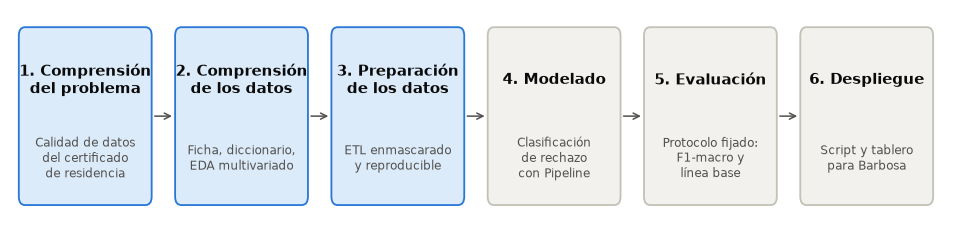

Interpretación (fig00_ruta_crispdm): Las tres primeras fases son el alcance de este avance y dejan listos los datos y las reglas de evaluación. El modelado y la evaluación se desarrollarán en las siguientes entregas. El despliegue queda como propuesta para Barbosa, cuya viabilidad depende del acceso a sus datos.


In [17]:
fases = [('1. Comprensión\ndel problema', 'Calidad de datos\ndel certificado\nde residencia', True), ('2. Comprensión\nde los datos', 'Ficha, diccionario,\nEDA multivariado', True), ('3. Preparación\nde los datos', 'ETL enmascarado\ny reproducible', True),
         ('4. Modelado', 'Clasificación\nde rechazo\ncon Pipeline', False), ('5. Evaluación', 'Protocolo fijado:\nF1-macro y\nlínea base', False), ('6. Despliegue', 'Script y tablero\npara Barbosa', False)]
fig, ax = plt.subplots(figsize=(11, 2.5)); ax.set_xlim(0, 6); ax.set_ylim(0, 1); ax.axis('off')
for i, (t, d, actual) in enumerate(fases):
    ax.add_patch(matplotlib.patches.FancyBboxPatch((i+.05, .08), .85, .84, boxstyle='round,pad=0,rounding_size=.04', fc='#dcebfa' if actual else '#f2f1ee', ec=AZUL if actual else '#c3c2b7', lw=1.2))
    ax.text(i+.475, .67, t, ha='center', va='center', fontsize=9.5, fontweight='bold'); ax.text(i+.475, .3, d, ha='center', va='center', fontsize=8, color=TINTA2)
    if i < 5:
        ax.annotate('', xy=(i+1.05, .5), xytext=(i+.9, .5), arrowprops=dict(arrowstyle='->', color=TINTA2))
guardar_figura(fig, 'fig00_ruta_crispdm', 'Fases de CRISP-DM adaptadas al proyecto; en azul, las trabajadas en el ACA 1')
interpretar('fig00_ruta_crispdm', 'Las tres primeras fases son el alcance de este avance y dejan listos los datos y las reglas de evaluación. El modelado y la evaluación se desarrollarán en las siguientes entregas. El despliegue queda como propuesta para Barbosa, cuya viabilidad depende del acceso a sus datos.')

## 14. Cierre y reproducibilidad

In [18]:
RES['segundos_total'] = round(time.perf_counter() - INICIO_EJECUCION, 2)
RES['semilla'] = SEMILLA
(BASE/'reports/resultados.json').write_text(json.dumps(RES, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
c.drop(columns=['dias_desde_inicio', 'volumen_dia', 'frecuencia_barrio']).to_csv(PROC/'cartagena_limpio.csv', index=False, encoding='utf-8')
v.drop(columns=['fecha_dia', 'dias_desde_inicio', 'volumen_dia']).to_csv(PROC/'villavicencio_limpio.csv', index=False, encoding='utf-8')
for carpeta in (PROC, RAW):
    for archivo in carpeta.glob('*.csv'):
        texto = archivo.read_text(encoding='utf-8')
        assert not re.search(r'(?<![\d/.:-])\d{10}(?![\d-])', texto), f'Posible identificador en {archivo.name}'
print('Sin identificadores de 10 dígitos en data/. Ejecución completa en', RES['segundos_total'], 's')

Sin identificadores de 10 dígitos en data/. Ejecución completa en 11.87 s
